# UTS Analisis Data Spasial — Part 1 (Take Home Test)
## Analisis Peta Titik Kebakaran Hutan dan Lahan di Indonesia, Tahun 2026

**Dosen:** Andi Pujo Rahadi, M.Sc.
**Nama / NIM:** *Boma Satrio Wicaksono Dewantoro / 52250061*


---
### Ketentuan soal dan di mana jawabannya
Soal: *Menganalisis peta kebakaran hutan di Indonesia menggunakan Python.*

| No | Ketentuan dari dosen | Dijawab di | Ringkasan jawaban |
|---|---|---|---|
| 1 | Mencari dataset **terkini (terbaru)** titik-titik kebakaran hutan di Indonesia yang memiliki informasi geometry (longitude dan latitude) | **Bagian 1** | NASA FIRMS (VIIRS NOAA-21, resolusi 375 m), data **1 Januari sampai 7 November 2026**; kolom `longitude` dan `latitude` diubah menjadi geometry `Point`; titik disaring agar hanya kebakaran vegetasi |
| 2 | Menentukan sistem CRS yang digunakan menggunakan salah satu sistem EPSG | **Bagian 2** | **EPSG:4326 (WGS 84)**; EPSG:6933 (equal-area) khusus untuk menghitung luas |
| 3 | Menggambarkan peta lokasi kebakaran hutan dengan gradasi warna (choropleth) menggunakan Python | **Bagian 5 dan 6** | Choropleth jumlah titik kebakaran per provinsi + warna titik menurut tingkat panas (FRP), dibuat dengan GeoPandas dan Matplotlib |
| 4 | Melengkapi dengan legends, north arrow, titles, dan sebagainya | **Bagian 6 dan 7** | Judul, legenda, colorbar, north arrow, skala, grid, sumber data, dan CRS |

**Deliverables**

| No | Deliverable | Keterangan |
|---|---|---|
| 1 | Jupyter notebook | File notebook ini |
| 2 | Dataset (sertakan URL dataset di dalam notebook) | URL ada di **Bagian 1.1** (tabel "Sumber dataset dan URL"); file datanya: `DL_FIRE_J2V-C2_840020.zip` |
| 3 | Peta dalam format png atau jpeg | **PNG**: `peta_titik_kebakaran_indonesia_2026.png` (peta nasional) dan peta tiap wilayah; semua gambar dikemas di **Bagian 9** |

Sebagai tambahan (nilai lebih): tren waktu harian dan bulanan (**Bagian 4**) dan peta zoom tujuh wilayah (**Bagian 7**).

### Catatan istilah — mohon dibaca
> Data kebakaran dari satelit secara resmi disebut **hotspot (titik panas)**: satelit mendeteksi anomali panas di permukaan bumi, bukan mengonfirmasi kebakaran satu per satu di lapangan. Agar hasilnya sedekat mungkin dengan **titik kebakaran**, data di notebook ini **disaring dalam tiga tahap** (Bagian 1.6 dan 1.8): (1) membuang gunung api, sumber panas statis (industri/flare), dan deteksi lepas pantai; (2) membuang titik berkeyakinan rendah; (3) hanya menyimpan titik yang berada di dalam provinsi Indonesia. Karena itu, istilah **"titik kebakaran"** dalam notebook ini berarti **titik kebakaran vegetasi hasil deteksi satelit yang telah disaring**, **bukan** data yang diverifikasi langsung di lapangan.

### Cara memakai notebook ini
1. **Data kebakaran diunggah manual.** Di **Google Colab**, jalankan notebook dari atas; saat sel konfigurasi (Bagian 0) berjalan dan file belum ditemukan, akan muncul tombol **"Choose Files"**. Klik tombol itu, lalu pilih `DL_FIRE_J2V-C2_840020.zip` (**jangan diekstrak**). Di komputer sendiri, cukup taruh zip di folder yang sama dengan notebook.
2. **Batas provinsi diunduh otomatis** dari GitHub, tidak perlu diunggah.
3. Jalankan semua sel (*Run All*). Prosesnya beberapa menit karena datanya besar (ratusan ribu titik).
4. **Semua gambar bisa diunduh.** Setiap grafik dan peta otomatis disimpan sebagai PNG, dan **Bagian 9** (sel terakhir) mengemasnya menjadi satu file zip yang langsung terunduh di Colab.
5. Setiap tabel, grafik, atau peta **diikuti kotak penjelasan berawalan "Artinya"** yang menjelaskan hasilnya dengan bahasa sehari-hari, lengkap dengan angka dari data.

### Daftar isi
0. Persiapan
1. Dataset titik kebakaran, informasi geometry, dan penyaringan
2. Penentuan CRS (EPSG)
3. Spatial join dan agregasi per provinsi
4. Tren waktu (harian dan bulanan)
5. Peta choropleth dan peta tingkat panas
6. Peta akhir lengkap
7. Peta zoom per wilayah
8. Interpretasi, keterbatasan, kesimpulan, dan pemeriksaan akhir
9. Unduh hasil (semua gambar)

---
## 0. Persiapan
**Library yang dipakai:** `pandas` (tabel), `geopandas` (data spasial), `matplotlib` (grafik dan peta), `mapclassify` (pengelompokan warna).
Jika belum terpasang: `pip install geopandas mapclassify matplotlib pandas`

In [1]:
# pasang otomatis paket yang belum ada (mis. mapclassify di Google Colab)
import importlib, subprocess, sys
for _paket in ["geopandas", "mapclassify"]:
    try:
        importlib.import_module(_paket)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _paket])

import os
import urllib.request

import numpy as np
import pandas as pd
import geopandas as gpd
import mapclassify
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.dpi"] = 110

# ---------- simpan otomatis SEMUA gambar agar bisa diunduh ----------
import re
os.makedirs("gambar_output", exist_ok=True)
_show_asli = plt.show
_nomor = [0]


def _slug(teks):
    t = re.sub(r"[^A-Za-z0-9]+", "_", teks.strip().split("\n")[0]).strip("_")
    return t[:70] or "gambar"


def _show_dan_simpan(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        judul = fig._suptitle.get_text() if getattr(fig, "_suptitle", None) is not None else ""
        if not judul and fig.axes:
            judul = fig.axes[0].get_title()
        _nomor[0] += 1
        fig.savefig(f"gambar_output/{_nomor[0]:02d}_{_slug(judul)}.png", dpi=200, bbox_inches="tight")
    _show_asli(*args, **kwargs)


plt.show = _show_dan_simpan

# ---------- Fungsi bantu ----------
BULAN = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli",
         "Agustus", "September", "Oktober", "November", "Desember"]
BULAN_PENDEK = [b[:3] for b in BULAN]


def angka(x, d=0):
    # format angka gaya Indonesia: 1.234,5
    s = f"{x:,.{d}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")


def pct(x):
    return angka(x * 100, 1) + "%"


def tgl_id(ts):
    return f"{ts.day} {BULAN[ts.month - 1]} {ts.year}"


def jelaskan(teks, judul="Artinya"):
    # kotak penjelasan awam di bawah setiap output
    baris = teks.strip().split("\n")
    isi = "\n".join(("> " + b) if b.strip() else ">" for b in baris)
    display(Markdown(f"> **{judul}**\n>\n{isi}"))


print("geopandas versi:", gpd.__version__)
jelaskan("Semua alat (library) yang dibutuhkan sudah siap dipakai. Bagian ini hanya persiapan, belum ada hasil analisis.")

geopandas versi: 1.2.0


> **Artinya**
>
> Semua alat (library) yang dibutuhkan sudah siap dipakai. Bagian ini hanya persiapan, belum ada hasil analisis.

In [2]:
# ====================== KONFIGURASI ======================
# Data kebakaran dari NASA FIRMS (zip berisi file arsip + NRT). JANGAN diekstrak.
# Data diunggah MANUAL: di Google Colab, tombol "Choose Files" muncul otomatis jika file belum ditemukan.
# Di komputer sendiri, taruh zip di folder yang sama dengan notebook.
FIRE_SOURCES = ["DL_FIRE_J2V-C2_840020.zip"]      # VIIRS NOAA-21

TAHUN = 2026            # hanya baris dengan tahun ini yang dipakai
SATELIT = None          # None = otomatis pilih satelit terbanyak
UKURAN_SEL = 0.01       # ukuran sel (derajat, kira-kira 1,1 km) untuk menandai lokasi sumber panas statis

PROV_PATH = "indonesia-38-provinces.geojson"   # batas 38 provinsi (diunduh otomatis dari GitHub)
PROV_URL = ("https://raw.githubusercontent.com/denyherianto/"
            "indonesia-geojson-topojson-maps-with-38-provinces/main/GeoJSON/indonesia-38-provinces.geojson")
# =========================================================

import zipfile


def cari_file(nama):
    # cari file di folder kerja, /content (Colab), lalu folder paling luar
    for folder in [".", "/content", "/"]:
        p = os.path.join(folder, nama)
        if os.path.exists(p):
            return p
    return None


# --- batas provinsi: diunduh otomatis dari GitHub ---
if not os.path.exists(PROV_PATH):
    print("Mengunduh batas provinsi dari GitHub ...")
    urllib.request.urlretrieve(PROV_URL, PROV_PATH)

# --- data kebakaran: diunggah manual ---
lokasi = [cari_file(f) for f in FIRE_SOURCES]
if any(p is None for p in lokasi):
    try:
        from google.colab import files as colab_files
        print("File data kebakaran belum ditemukan.")
        print("Klik tombol 'Choose Files' di bawah ini, lalu pilih zip dari FIRMS (jangan diekstrak) ...")
        diunggah = colab_files.upload()
        FIRE_SOURCES = [n for n in diunggah if n.lower().endswith((".zip", ".csv"))]
        lokasi = [cari_file(f) for f in FIRE_SOURCES]
    except ImportError:
        pass        # bukan Google Colab

if (not lokasi) or any(p is None for p in lokasi):
    raise FileNotFoundError("File data kebakaran belum ditemukan. Di Colab: jalankan ulang sel ini lalu unggah zip lewat tombol "
                            "'Choose Files'. Di komputer sendiri: taruh zip di folder yang sama dengan notebook.")
FIRE_SOURCES = lokasi

for f in FIRE_SOURCES:
    print("File data kebakaran ditemukan :", f)
print("Batas provinsi ditemukan      :", PROV_PATH)

jelaskan("Data kebakaran (zip dari NASA FIRMS) diunggah secara manual, sedangkan batas provinsi diunduh otomatis dari GitHub. "
         "Jika kedua file sudah ditemukan, data siap dibaca. Jika file belum ada, di Google Colab akan muncul tombol unggah; "
         "pilih file zip-nya dan tunggu sampai selesai.")

File data kebakaran ditemukan : ./DL_FIRE_J2V-C2_840020.zip
Batas provinsi ditemukan      : indonesia-38-provinces.geojson


> **Artinya**
>
> Data kebakaran (zip dari NASA FIRMS) diunggah secara manual, sedangkan batas provinsi diunduh otomatis dari GitHub. Jika kedua file sudah ditemukan, data siap dibaca. Jika file belum ada, di Google Colab akan muncul tombol unggah; pilih file zip-nya dan tunggu sampai selesai.

---
## 1. Dataset titik kebakaran, informasi geometry, dan penyaringan

### 1.1 Sumber data dan alasan memilih sensor
| Data | Sumber | Keterangan |
|---|---|---|
| Titik kebakaran (hasil deteksi satelit) | **NASA FIRMS** (Fire Information for Resource Management System), sensor **VIIRS** pada satelit **NOAA-21**, produk 375 m | Data terbuka; satu baris = satu piksel (±375 m) yang terdeteksi jauh lebih panas dari sekitarnya |
| Batas provinsi | GeoJSON 38 provinsi Indonesia (repo `denyherianto/indonesia-geojson-topojson-maps-with-38-provinces`) | Sudah memuat provinsi pemekaran Papua |

**Mengapa NOAA-21?** Dari lima file yang diunduh, ada empat sensor berbeda. Memakai beberapa sensor sekaligus membuat satu kebakaran terhitung berkali-kali, jadi dipilih **satu sensor saja**:

| Sensor | Resolusi | Baris (arsip + NRT) | Cakupan tanggal | Catatan |
|---|---|---|---|---|
| **VIIRS NOAA-21** | **375 m** | ±661 ribu | 7 Nov 2025 – 7 Nov 2026 | **Dipilih**: resolusi detail dan data paling mutakhir |
| VIIRS NOAA-20 | 375 m | ±673 ribu | 7 Nov 2025 – 7 Nov 2026 | Hampir setara, tidak dipilih agar tidak ganda |
| VIIRS Suomi-NPP | 375 m | ±640 ribu | 7 Nov 2025 – 2 Nov 2026 | Berhenti lebih awal |
| MODIS (Aqua + Terra) | 1 km | ±144 ribu | 7 Nov 2025 – 7 Nov 2026 | Resolusi lebih kasar |

File `titik_panas_andre.zip` tidak dipakai karena isinya identik dengan sebagian file Suomi-NPP.

**Arsip dan NRT.** Setiap zip berisi dua jenis file: **arsip** (data standar yang sudah diproses ulang NASA, di sini sampai 31 Juli 2026) dan **NRT / near real-time** (data cepat yang bersifat sementara, 1 Agustus sampai 7 November 2026). Keduanya digabung dan tidak saling tumpang tindih.

### Sumber dataset dan URL
| Dataset | URL | Keterangan |
|---|---|---|
| Titik kebakaran (hasil deteksi satelit): NASA FIRMS, VIIRS NOAA-21 375 m | https://firms.modaps.eosdis.nasa.gov/download/ | Halaman *Archive Download* FIRMS. Permintaan unduhan yang dipakai: nomor **840020** (`DL_FIRE_J2V-C2_840020.zip`), sensor VIIRS NOAA-21, area Indonesia, 7 Nov 2025 sampai 7 Nov 2026 (arsip sampai 31 Jul 2026, NRT 1 Agu sampai 7 Nov 2026), format CSV |
| Halaman utama NASA FIRMS | https://firms.modaps.eosdis.nasa.gov/ | Penjelasan produk, atribut data, dan data titik api terkini |
| Batas 38 provinsi Indonesia (GeoJSON) | https://raw.githubusercontent.com/denyherianto/indonesia-geojson-topojson-maps-with-38-provinces/main/GeoJSON/indonesia-38-provinces.geojson | Diunduh otomatis oleh notebook; repositori: https://github.com/denyherianto/indonesia-geojson-topojson-maps-with-38-provinces |

> **Catatan:** unduhan FIRMS dibuat lewat *permintaan* (request) di halaman unduh, sehingga hasilnya berupa file zip, bukan tautan langsung yang tetap. Karena itu dicantumkan halaman unduhnya beserta parameter permintaan di atas, dan file zip-nya ikut dikumpulkan sebagai dataset. Untuk mendapatkan data yang sama atau yang lebih baru, buka URL halaman unduh, pilih sensor VIIRS NOAA-21, area Indonesia, rentang tanggal, dan format CSV.

### 1.2 Membaca file

In [3]:
KOLOM_PAKAI = {"latitude", "longitude", "acq_date", "acq_time", "satellite",
               "confidence", "frp", "daynight", "brightness", "type"}


def baca_firms(path):
    # baca semua CSV di dalam zip (atau satu file CSV) tanpa mengekstrak ke disk
    hasil = []
    if path.lower().endswith(".zip"):
        with zipfile.ZipFile(path) as z:
            for n in z.namelist():
                if n.lower().endswith(".csv"):
                    with z.open(n) as f:
                        d = pd.read_csv(f, usecols=lambda c: c in KOLOM_PAKAI, low_memory=False)
                    hasil.append((os.path.basename(n), d))
    else:
        d = pd.read_csv(path, usecols=lambda c: c in KOLOM_PAKAI, low_memory=False)
        hasil.append((os.path.basename(path), d))
    return hasil


bagian, ringkas_file = [], []
for p in FIRE_SOURCES:
    for nama_file, d in baca_firms(p):
        is_arsip = "archive" in nama_file.lower()
        d["sumber_file"] = "arsip" if is_arsip else "nrt"
        ringkas_file.append({
            "File": nama_file,
            "Jenis": "arsip (data standar)" if is_arsip else "NRT (near real-time)",
            "Jumlah baris": len(d),
            "Tanggal awal": d["acq_date"].min(),
            "Tanggal akhir": d["acq_date"].max(),
            "Punya kolom 'type'": "type" in d.columns,
        })
        bagian.append(d)

df = pd.concat(bagian, ignore_index=True)
n_mentah = len(df)

wajib = ["latitude", "longitude", "acq_date", "frp", "confidence", "satellite"]
hilang = [k for k in wajib if k not in df.columns]
if hilang:
    raise ValueError(f"Kolom wajib tidak ditemukan: {hilang}. Pastikan file berasal dari NASA FIRMS (VIIRS).")

tabel_file = pd.DataFrame(ringkas_file)
display(tabel_file)

jelaskan(
    f"Notebook membaca langsung isi zip tanpa perlu diekstrak. Ada **{len(tabel_file)} file** dengan total **{angka(n_mentah)} baris**, "
    "yaitu satu file **arsip** dan satu file **NRT**.\n\n"
    "- **Arsip** adalah data standar yang sudah diperiksa dan diproses ulang NASA, sehingga lebih rapi dan punya kolom tambahan **type** "
    "(jenis sumber panas).\n"
    "- **NRT** adalah data cepat yang bersifat sementara, tersedia hanya beberapa jam setelah satelit lewat, dan **tidak punya kolom type**.\n\n"
    "Kedua file sambung-menyambung berdasarkan tanggal sehingga bisa digabung menjadi satu rangkaian waktu."
)

,File,Jenis,Jumlah baris,Tanggal awal,Tanggal akhir,Punya kolom 'type'
0,fire_archive_J2V-C2_840020.csv,arsip (data standar),66212,2025-11-07,2026-07-31,True
1,fire_nrt_J2V-C2_840020.csv,NRT (near real-time),594926,2026-08-01,2026-11-07,False


> **Artinya**
>
> Notebook membaca langsung isi zip tanpa perlu diekstrak. Ada **2 file** dengan total **661.138 baris**, yaitu satu file **arsip** dan satu file **NRT**.
>
> - **Arsip** adalah data standar yang sudah diperiksa dan diproses ulang NASA, sehingga lebih rapi dan punya kolom tambahan **type** (jenis sumber panas).
> - **NRT** adalah data cepat yang bersifat sementara, tersedia hanya beberapa jam setelah satelit lewat, dan **tidak punya kolom type**.
>
> Kedua file sambung-menyambung berdasarkan tanggal sehingga bisa digabung menjadi satu rangkaian waktu.

### 1.3 Pembersihan data
Langkah yang dilakukan, berurutan:
1. Ubah kolom tanggal menjadi tipe tanggal.
2. Jika ada lebih dari satu satelit, pakai **satu satelit saja** agar kebakaran yang sama tidak terhitung ganda.
3. Samakan penulisan tingkat keyakinan (`confidence`), karena FIRMS memakai huruf (`l/n/h`) pada VIIRS dan angka 0-100 pada MODIS.
4. **Buang duplikat** (baris yang sama persis).
5. Simpan salinan data **arsip** (termasuk akhir 2025) untuk membangun penanda sumber panas statis di Bagian 1.6.
6. Simpan **hanya tahun yang dipilih** (`TAHUN`).

In [4]:
def normal_conf(x):
    # samakan penulisan confidence: l/n/h atau angka -> low/nominal/high
    if pd.isna(x):
        return x
    s = str(x).strip().lower()
    if s in ("l", "low"):
        return "low"
    if s in ("n", "nominal"):
        return "nominal"
    if s in ("h", "high"):
        return "high"
    try:
        v = float(s)
        return "low" if v < 30 else ("nominal" if v < 80 else "high")
    except ValueError:
        return s


# 1. tanggal
df["acq_date"] = pd.to_datetime(df["acq_date"])

# 2. satu satelit saja
cacah_satelit = df["satellite"].value_counts()
SATELIT_PAKAI = cacah_satelit.index[0] if SATELIT is None else SATELIT
df = df[df["satellite"] == SATELIT_PAKAI].copy()
n_satelit = len(df)

# 3. confidence + format jam
df["confidence"] = df["confidence"].map(normal_conf)
if "acq_time" in df.columns:
    df["acq_time"] = df["acq_time"].astype(str).str.replace(":", "", regex=False).str.zfill(4)

# 4. buang duplikat
kunci = [k for k in ["latitude", "longitude", "acq_date", "acq_time", "satellite"] if k in df.columns]
df = df.drop_duplicates(subset=kunci).reset_index(drop=True)
n_tanpa_dup = len(df)

# 5. simpan arsip penuh (termasuk 2025) untuk penanda sumber statis
arsip_semua = df[df["sumber_file"] == "arsip"].copy()

# 6. filter tahun
df = df[df["acq_date"].dt.year == TAHUN].copy().reset_index(drop=True)
n_tahun = len(df)

tgl_min, tgl_max = df["acq_date"].min(), df["acq_date"].max()
n_hari = (tgl_max - tgl_min).days + 1
PERIODE = tgl_id(tgl_min) if tgl_min == tgl_max else f"{tgl_id(tgl_min)} s/d {tgl_id(tgl_max)}"

FUNNEL = [("Baris mentah (arsip + NRT)", n_mentah),
          (f"Tahun {TAHUN}, satelit {SATELIT_PAKAI}, tanpa duplikat", n_tahun)]

print(f"Baris mentah (semua file)           : {n_mentah:,}")
print(f"Setelah pilih satelit {SATELIT_PAKAI!r:8}      : {n_satelit:,}")
print(f"Setelah buang duplikat              : {n_tanpa_dup:,}")
print(f"Setelah filter tahun {TAHUN}           : {n_tahun:,}")
print(f"Periode data                        : {PERIODE} ({n_hari} hari)")
print("Satelit yang ada di data            :", cacah_satelit.to_dict())

jelaskan(
    f"Setiap baris data adalah **satu titik panas hasil deteksi satelit** pada satu waktu tertentu.\n\n"
    f"Dari {angka(n_mentah)} baris mentah, yang tersisa **{angka(n_tahun)} baris** untuk tahun {TAHUN} "
    f"(sisanya dibuang karena berasal dari tahun 2025, dari satelit lain, atau duplikat). "
    f"Data mencakup **{PERIODE}** ({angka(n_hari)} hari). "
    + ("Karena data berhenti sebelum akhir tahun, hasil analisis hanya berlaku sampai tanggal tersebut, bukan satu tahun penuh. "
       if tgl_max < pd.Timestamp(TAHUN, 12, 31) else "")
    + f"Satelit yang dipakai adalah **{SATELIT_PAKAI}** (NOAA-21). Titik-titik ini **belum disaring** menjadi titik kebakaran; penyaringan dilakukan di Bagian 1.6."
)

Baris mentah (semua file)           : 661,138
Setelah pilih satelit 'N21'         : 661,138
Setelah buang duplikat              : 661,138
Setelah filter tahun 2026           : 657,377
Periode data                        : 1 Januari 2026 s/d 7 November 2026 (311 hari)
Satelit yang ada di data            : {'N21': 661138}


> **Artinya**
>
> Setiap baris data adalah **satu titik panas hasil deteksi satelit** pada satu waktu tertentu.
>
> Dari 661.138 baris mentah, yang tersisa **657.377 baris** untuk tahun 2026 (sisanya dibuang karena berasal dari tahun 2025, dari satelit lain, atau duplikat). Data mencakup **1 Januari 2026 s/d 7 November 2026** (311 hari). Karena data berhenti sebelum akhir tahun, hasil analisis hanya berlaku sampai tanggal tersebut, bukan satu tahun penuh. Satelit yang dipakai adalah **N21** (NOAA-21). Titik-titik ini **belum disaring** menjadi titik kebakaran; penyaringan dilakukan di Bagian 1.6.

### 1.4 Contoh isi data dan arti kolom

In [5]:
cols_tampil = [c for c in ["latitude", "longitude", "acq_date", "acq_time", "satellite",
                           "confidence", "brightness", "frp", "daynight", "type"] if c in df.columns]
display(df[cols_tampil].head())

jelaskan(
    "Tabel di atas adalah 5 titik pertama dari data. Cara membacanya per kolom:\n\n"
    "- **latitude / longitude**: letak titik di bumi (lintang dan bujur). Inilah informasi *geometry* yang diminta soal.\n"
    "- **acq_date / acq_time**: tanggal dan jam (UTC) satelit mendeteksi titik tersebut.\n"
    "- **confidence**: seberapa yakin satelit bahwa itu benar-benar titik panas (low = kurang yakin, high = sangat yakin).\n"
    "- **brightness**: suhu piksel dalam Kelvin; makin tinggi, makin panas.\n"
    "- **frp**: kekuatan panas/energi api dalam megawatt (MW). Makin besar angkanya, makin besar apinya.\n"
    "- **type**: jenis sumber panas (hanya ada di data arsip; kosong untuk data NRT). Dijelaskan di Bagian 1.6."
)

,latitude,longitude,acq_date,acq_time,satellite,confidence,brightness,frp,daynight,type
0,-2.81,129.49,2026-01-01,0443,N21,nominal,330.52,3.01,D,0.00
1,-3.87,122.41,2026-01-01,0443,N21,nominal,325.26,4.01,D,2.00
2,-3.86,138.60,2026-01-01,0443,N21,nominal,344.44,19.96,D,0.00
3,-3.81,138.62,2026-01-01,0443,N21,nominal,339.58,11.10,D,0.00
4,-3.81,138.62,2026-01-01,0443,N21,nominal,334.24,14.31,D,0.00


> **Artinya**
>
> Tabel di atas adalah 5 titik pertama dari data. Cara membacanya per kolom:
>
> - **latitude / longitude**: letak titik di bumi (lintang dan bujur). Inilah informasi *geometry* yang diminta soal.
> - **acq_date / acq_time**: tanggal dan jam (UTC) satelit mendeteksi titik tersebut.
> - **confidence**: seberapa yakin satelit bahwa itu benar-benar titik panas (low = kurang yakin, high = sangat yakin).
> - **brightness**: suhu piksel dalam Kelvin; makin tinggi, makin panas.
> - **frp**: kekuatan panas/energi api dalam megawatt (MW). Makin besar angkanya, makin besar apinya.
> - **type**: jenis sumber panas (hanya ada di data arsip; kosong untuk data NRT). Dijelaskan di Bagian 1.6.

| Kolom | Arti |
|---|---|
| `latitude`, `longitude` | Lintang dan bujur pusat piksel (derajat) |
| `brightness` | Suhu kecerahan piksel (Kelvin) |
| `frp` | *Fire Radiative Power* (MW): energi radiasi api, indikator intensitas |
| `confidence` | Tingkat keyakinan deteksi: low / nominal / high |
| `acq_date`, `acq_time` | Tanggal dan jam akuisisi (UTC) |
| `satellite` | Satelit (N21 = NOAA-21) |
| `daynight` | D = siang, N = malam |
| `type` | 0 = kebakaran vegetasi (diduga), 1 = gunung api aktif, 2 = sumber panas statis darat lain, 3 = deteksi lepas pantai |

### 1.5 Pemeriksaan kualitas data

In [6]:
kosong = df[[c for c in cols_tampil if c != "type"]].isna().sum()
dup = df.duplicated(subset=kunci).sum()

print("Nilai kosong per kolom (kolom 'type' dikecualikan karena memang kosong di data NRT):")
print(kosong.to_string())
print()
print("Baris duplikat           :", dup)
print("Tanggal paling awal      :", tgl_min.date())
print("Tanggal paling akhir     :", tgl_max.date())

jelaskan(
    "Ini seperti memeriksa kelengkapan formulir sebelum dianalisis.\n\n"
    + ("**Tidak ada kolom yang kosong**, artinya datanya lengkap. " if kosong.sum() == 0
       else f"Ada **{int(kosong.sum())} sel kosong** pada kolom tertentu (lihat daftar di atas); sebaiknya diperiksa. ")
    + ("Tidak ada baris ganda, jadi tidak ada titik yang terhitung dua kali." if dup == 0
       else f"Masih ada {dup} baris ganda yang perlu diperiksa.")
)

Nilai kosong per kolom (kolom 'type' dikecualikan karena memang kosong di data NRT):
latitude      0
longitude     0
acq_date      0
acq_time      0
satellite     0
confidence    0
brightness    0
frp           0
daynight      0

Baris duplikat           : 0
Tanggal paling awal      : 2026-01-01
Tanggal paling akhir     : 2026-11-07


> **Artinya**
>
> Ini seperti memeriksa kelengkapan formulir sebelum dianalisis.
>
> **Tidak ada kolom yang kosong**, artinya datanya lengkap. Tidak ada baris ganda, jadi tidak ada titik yang terhitung dua kali.

In [7]:
ringkas = df[["latitude", "longitude", "frp"] + (["brightness"] if "brightness" in df.columns else [])].describe()
display(ringkas)

jelaskan(
    "Tabel ini merangkum angka-angka utama. Baris **mean** = rata-rata, **50%** = nilai tengah (median), **min** dan **max** = nilai terkecil dan terbesar.\n\n"
    f"Untuk tingkat panas (**FRP**): nilai tengahnya {angka(df['frp'].median(), 1)} MW, "
    f"rata-ratanya {angka(df['frp'].mean(), 1)} MW, dan yang terbesar {angka(df['frp'].max(), 1)} MW. "
    "Rata-rata yang lebih tinggi dari nilai tengah menandakan **sebagian kecil api sangat besar**, sedangkan kebanyakan titik berupa api kecil."
)

,latitude,longitude,frp,brightness
count,"657,377.00","657,377.00","657,377.00","657,377.00"
mean,-3.29,118.10,8.53,328.69
std,2.81,11.41,15.39,17.44
min,-10.88,95.10,0.00,207.38
25%,-3.98,110.72,2.31,311.34
50%,-2.84,114.13,4.81,332.30
75%,-1.78,123.52,9.27,340.33
max,5.79,141.11,792.28,367.00


> **Artinya**
>
> Tabel ini merangkum angka-angka utama. Baris **mean** = rata-rata, **50%** = nilai tengah (median), **min** dan **max** = nilai terkecil dan terbesar.
>
> Untuk tingkat panas (**FRP**): nilai tengahnya 4,8 MW, rata-ratanya 8,5 MW, dan yang terbesar 792,3 MW. Rata-rata yang lebih tinggi dari nilai tengah menandakan **sebagian kecil api sangat besar**, sedangkan kebanyakan titik berupa api kecil.

In [8]:
valid = df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180)
print("Koordinat valid  :", int(valid.sum()), "dari", len(df))
print(f"Lintang : {df.latitude.min():.2f}  s/d  {df.latitude.max():.2f}")
print(f"Bujur   : {df.longitude.min():.2f}  s/d  {df.longitude.max():.2f}")

jelaskan(
    f"Koordinat diperiksa agar tidak ada titik yang 'jatuh' di luar bumi (lintang harus -90 sampai 90, bujur -180 sampai 180). "
    f"Hasilnya **{angka(int(valid.sum()))} dari {angka(len(df))} titik valid**.\n\n"
    f"Rentang koordinatnya (lintang {df.latitude.min():.1f} sampai {df.latitude.max():.1f}, bujur {df.longitude.min():.1f} sampai {df.longitude.max():.1f}) "
    "berupa kotak yang menutupi seluruh Indonesia, sehingga sebagian titik di tepinya bisa berada di negara tetangga atau di laut. "
    "Titik seperti itu akan tersaring otomatis pada langkah *spatial join* di Bagian 3."
)

Koordinat valid  : 657377 dari 657377
Lintang : -10.88  s/d  5.79
Bujur   : 95.10  s/d  141.11


> **Artinya**
>
> Koordinat diperiksa agar tidak ada titik yang 'jatuh' di luar bumi (lintang harus -90 sampai 90, bujur -180 sampai 180). Hasilnya **657.377 dari 657.377 titik valid**.
>
> Rentang koordinatnya (lintang -10.9 sampai 5.8, bujur 95.1 sampai 141.1) berupa kotak yang menutupi seluruh Indonesia, sehingga sebagian titik di tepinya bisa berada di negara tetangga atau di laut. Titik seperti itu akan tersaring otomatis pada langkah *spatial join* di Bagian 3.

### 1.6 Penyaringan: dari titik panas menjadi titik kebakaran vegetasi
Satelit mendeteksi **semua sumber panas**, bukan hanya kebakaran. Karena soal meminta *titik kebakaran*, sumber panas yang jelas bukan kebakaran vegetasi dibuang lebih dulu:

- **Langkah A (data arsip):** pakai kolom `type`. Hanya `type = 0` (kebakaran vegetasi) yang disimpan; gunung api aktif (1), sumber panas statis seperti industri atau *gas flare* (2), dan deteksi lepas pantai (3) dibuang.
- **Langkah B (data NRT):** data NRT tidak punya kolom `type`, padahal mencakup Agustus-November (periode puncak). Solusinya: lokasi sumber panas statis dan gunung api dari data arsip dicatat dalam **sel kotak ±1 km**, lalu titik NRT yang jatuh di sel itu dibuang, karena sumber statis menyala di tempat yang sama berulang-ulang. Ketepatan metode ini diuji dulu sebelum dipakai.

Penyaringan tingkat keyakinan (`confidence`) dilakukan di Bagian 1.8.

#### Langkah A: menyaring data arsip dengan kolom `type`

,Jenis sumber panas,Jumlah titik,Persen
0,Kebakaran vegetasi (diduga),52095,"83,4%"
1,Gunung api aktif,1571,"2,5%"
2,Sumber panas statis lain (industri/flare),8253,"13,2%"
3,Deteksi lepas pantai,532,"0,9%"


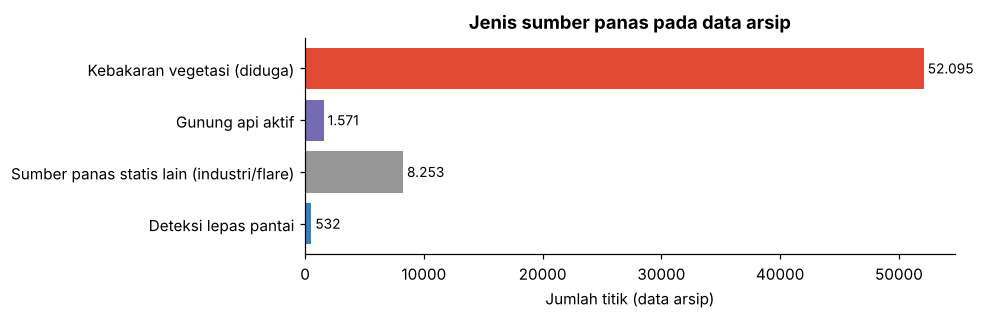

> **Artinya**
>
> Satelit tidak hanya menangkap kebakaran. Tabel dan grafik ini memperlihatkan **apa saja yang tertangkap** pada data arsip.
>
> Sebanyak **83,4%** (52.095 titik) adalah kebakaran vegetasi. Sisanya, **16,6%**, adalah sumber panas lain: gunung api yang sedang aktif, fasilitas seperti kilang atau pembakaran gas (*flare*) yang menyala terus-menerus, dan deteksi di laut. Karena bukan kebakaran hutan atau lahan, titik-titik ini **dibuang**.

Titik arsip dibuang (type bukan 0): 10.356


In [9]:
nama_tipe = {0: "Kebakaran vegetasi (diduga)", 1: "Gunung api aktif",
             2: "Sumber panas statis lain (industri/flare)", 3: "Deteksi lepas pantai"}

arsip_th = df[df["sumber_file"] == "arsip"]
tipe = arsip_th["type"].value_counts().sort_index()
tab_tipe = pd.DataFrame({
    "Jenis sumber panas": [nama_tipe.get(int(k), str(k)) for k in tipe.index],
    "Jumlah titik": tipe.values,
    "Persen": [pct(v / tipe.sum()) for v in tipe.values],
})
display(tab_tipe)

fig, ax = plt.subplots(figsize=(9, 3))
warna_t = ["#e34a33", "#756bb1", "#969696", "#3182bd"]
ax.barh(tab_tipe["Jenis sumber panas"][::-1], tab_tipe["Jumlah titik"][::-1], color=warna_t[:len(tab_tipe)][::-1])
for i, v in enumerate(tab_tipe["Jumlah titik"][::-1]):
    ax.text(v, i, " " + angka(v), va="center", fontsize=9)
ax.set_xlabel("Jumlah titik (data arsip)")
ax.set_title("Jenis sumber panas pada data arsip", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

n_veg = int(tipe.get(0, 0))
jelaskan(
    "Satelit tidak hanya menangkap kebakaran. Tabel dan grafik ini memperlihatkan **apa saja yang tertangkap** pada data arsip.\n\n"
    f"Sebanyak **{pct(n_veg / tipe.sum())}** ({angka(n_veg)} titik) adalah kebakaran vegetasi. Sisanya, **{pct(1 - n_veg / tipe.sum())}**, "
    "adalah sumber panas lain: gunung api yang sedang aktif, fasilitas seperti kilang atau pembakaran gas (*flare*) yang menyala terus-menerus, "
    "dan deteksi di laut. Karena bukan kebakaran hutan atau lahan, titik-titik ini **dibuang**."
)

n_sebelum_tipe = len(df)
df = df[(df["sumber_file"] == "nrt") | (df["type"] == 0)].copy()
n_buang_tipe = n_sebelum_tipe - len(df)
print(f"Titik arsip dibuang (type bukan 0): {angka(n_buang_tipe)}")

#### Langkah B: menyaring data NRT dengan penanda sumber panas statis

In [10]:
def kunci_sel(lat, lon, ukuran=UKURAN_SEL):
    # ubah koordinat menjadi nomor sel kotak (±1 km) supaya titik yang berdekatan mudah dicocokkan
    i = np.round(np.asarray(lat) / ukuran).astype(np.int64) + 20000
    j = np.round(np.asarray(lon) / ukuran).astype(np.int64) + 20000
    return i * 100000 + j


# --- membangun penanda dari data arsip (type 1 dan 2) ---
statis_arsip = arsip_semua[arsip_semua["type"].isin([1, 2])]
kunci_statis = np.unique(kunci_sel(statis_arsip["latitude"], statis_arsip["longitude"]))

# --- uji ketepatan: bangun penanda dari paruh awal data, uji pada paruh akhir ---
a = arsip_semua.sort_values("acq_date")
paruh = len(a) // 2
awal, akhir = a.iloc[:paruh], a.iloc[paruh:]
aw_st = awal[awal["type"].isin([1, 2])]
k_awal = np.unique(kunci_sel(aw_st["latitude"], aw_st["longitude"]))
ak_st = akhir[akhir["type"].isin([1, 2])]
ak_veg = akhir[akhir["type"] == 0]
tertangkap = np.isin(kunci_sel(ak_st["latitude"], ak_st["longitude"]), k_awal).mean()
salah_buang = np.isin(kunci_sel(ak_veg["latitude"], ak_veg["longitude"]), k_awal).mean()

uji = pd.DataFrame({
    "Ukuran uji": ["Sumber statis di paruh akhir yang berhasil dikenali penanda (makin tinggi makin baik)",
                   "Kebakaran vegetasi di paruh akhir yang salah dibuang (makin rendah makin baik)"],
    "Hasil": [pct(tertangkap), pct(salah_buang)],
})
display(uji)

# --- menerapkan penanda pada data NRT ---
is_nrt = df["sumber_file"] == "nrt"
di_statis = np.isin(kunci_sel(df["latitude"], df["longitude"]), kunci_statis)
buang_nrt = is_nrt & di_statis
n_nrt_sebelum = int(is_nrt.sum())
n_buang_nrt = int(buang_nrt.sum())
df = df[~buang_nrt].copy().reset_index(drop=True)

print(f"Jumlah sel penanda sumber statis      : {len(kunci_statis):,}")
print(f"Titik NRT sebelum disaring             : {n_nrt_sebelum:,}")
print(f"Titik NRT dibuang (di lokasi statis)   : {n_buang_nrt:,}")
print(f"Total titik sekarang                   : {len(df):,}")

# periode dihitung ulang setelah penyaringan
tgl_min, tgl_max = df["acq_date"].min(), df["acq_date"].max()
n_hari = (tgl_max - tgl_min).days + 1
PERIODE = tgl_id(tgl_min) if tgl_min == tgl_max else f"{tgl_id(tgl_min)} s/d {tgl_id(tgl_max)}"
FUNNEL.append(("Setelah buang gunung api, sumber statis, lepas pantai", len(df)))

jelaskan(
    "Data NRT tidak punya keterangan jenis sumber panas, jadi dipakai **trik lokasi**: sumber panas statis (kilang, flare, gunung api) menyala di **tempat yang sama setiap hari**, "
    f"sedangkan kebakaran hutan berpindah-pindah. Dari data arsip dicatat **{angka(len(kunci_statis))} kotak kecil (±1 km)** tempat sumber seperti itu berada, "
    "lalu titik NRT yang jatuh di kotak itu dibuang.\n\n"
    f"**Apakah cara ini bisa dipercaya?** Diuji dengan membangun catatan dari paruh awal data lalu mencobanya pada paruh akhir: "
    f"**{pct(tertangkap)}** sumber statis berhasil dikenali, dan hanya **{pct(salah_buang)}** kebakaran vegetasi yang salah terbuang. "
    f"Pada data NRT, {angka(n_buang_nrt)} titik ({pct(n_buang_nrt / n_nrt_sebelum)}) dibuang. "
    "Keterbatasannya: sumber statis yang baru muncul setelah data arsip berakhir tidak akan dikenali."
)

,Ukuran uji,Hasil
0,Sumber statis di paruh akhir yang berhasil dik...,"98,0%"
1,Kebakaran vegetasi di paruh akhir yang salah d...,"0,8%"


Jumlah sel penanda sumber statis      : 255
Titik NRT sebelum disaring             : 594,926
Titik NRT dibuang (di lokasi statis)   : 10,966
Total titik sekarang                   : 636,055


> **Artinya**
>
> Data NRT tidak punya keterangan jenis sumber panas, jadi dipakai **trik lokasi**: sumber panas statis (kilang, flare, gunung api) menyala di **tempat yang sama setiap hari**, sedangkan kebakaran hutan berpindah-pindah. Dari data arsip dicatat **255 kotak kecil (±1 km)** tempat sumber seperti itu berada, lalu titik NRT yang jatuh di kotak itu dibuang.
>
> **Apakah cara ini bisa dipercaya?** Diuji dengan membangun catatan dari paruh awal data lalu mencobanya pada paruh akhir: **98,0%** sumber statis berhasil dikenali, dan hanya **0,8%** kebakaran vegetasi yang salah terbuang. Pada data NRT, 10.966 titik (1,8%) dibuang. Keterbatasannya: sumber statis yang baru muncul setelah data arsip berakhir tidak akan dikenali.

### 1.7 Membuat geometry titik
Dataset berupa tabel biasa. Agar menjadi **data spasial**, kolom `longitude` (sumbu x) dan `latitude` (sumbu y) diubah menjadi geometry bertipe `Point` memakai `gpd.points_from_xy()`.

> Urutan argumen harus **(x, y) = (longitude, latitude)**. Terbalik urutan adalah kesalahan paling umum.

In [11]:
titik = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
    crs="EPSG:4326",          # sistem koordinat asli data FIRMS (lihat Bagian 2)
)

print("Tipe objek     :", type(titik).__name__)
print("Tipe geometry  :", titik.geom_type.unique().tolist())
print("CRS            :", titik.crs)
display(titik[["latitude", "longitude", "frp", "confidence", "geometry"]].head())

jelaskan(
    "Tabel biasa sekarang diubah menjadi **peta digital**: setiap baris punya kolom baru bernama **geometry** yang berisi sebuah titik (*POINT*) "
    "di posisi lintang-bujurnya. Dengan begitu komputer bisa menggambar titik di peta dan menghitung titik mana yang berada di provinsi mana.\n\n"
    "**CRS EPSG:4326** adalah 'bahasa koordinat' yang dipakai: lintang-bujur biasa (seperti di Google Maps / GPS)."
)

Tipe objek     : GeoDataFrame
Tipe geometry  : ['Point']
CRS            : EPSG:4326


,latitude,longitude,frp,confidence,geometry
0,-2.81,129.49,3.01,nominal,POINT (129.49081 -2.81166)
1,-3.86,138.60,19.96,nominal,POINT (138.60455 -3.85501)
2,-3.81,138.62,11.10,nominal,POINT (138.62064 -3.80852)
3,-3.81,138.62,14.31,nominal,POINT (138.61909 -3.80779)
4,-2.29,121.68,5.73,nominal,POINT (121.6789 -2.28934)


> **Artinya**
>
> Tabel biasa sekarang diubah menjadi **peta digital**: setiap baris punya kolom baru bernama **geometry** yang berisi sebuah titik (*POINT*) di posisi lintang-bujurnya. Dengan begitu komputer bisa menggambar titik di peta dan menghitung titik mana yang berada di provinsi mana.
>
> **CRS EPSG:4326** adalah 'bahasa koordinat' yang dipakai: lintang-bujur biasa (seperti di Google Maps / GPS).

### 1.8 Eksplorasi awal: kualitas deteksi dan intensitas

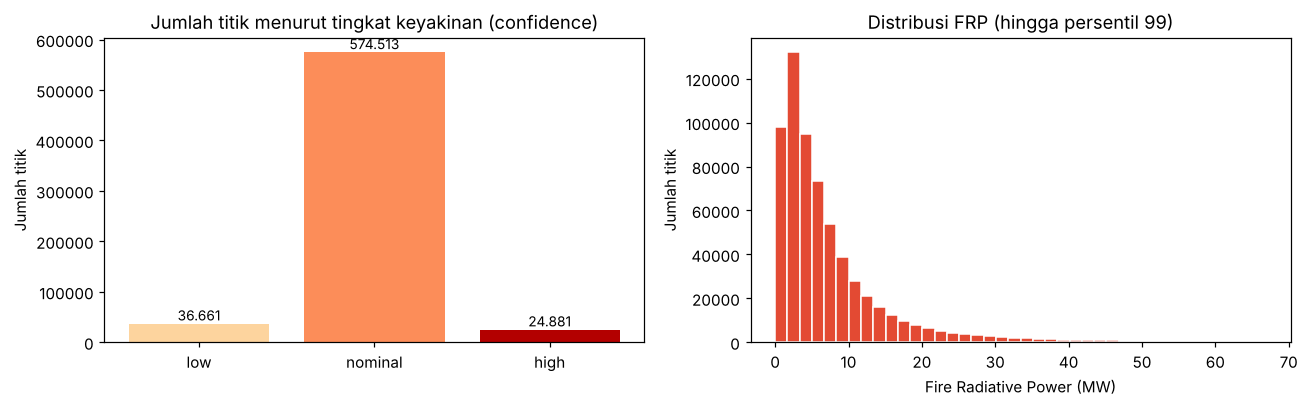

> **Artinya**
>
> **Grafik kiri** menunjukkan seberapa yakin satelit pada tiap titik. Sebanyak **5,8%** titik berstatus *low* (kurang yakin), 90,3% *nominal* (cukup yakin), dan 3,9% *high* (sangat yakin). Titik *low* paling mungkin berupa deteksi keliru, sehingga akan dibuang.
>
> **Grafik kanan** menunjukkan seberapa besar api pada tiap titik. Batang tertinggi berada di sisi kiri (api kecil), lalu menurun ke kanan: kebanyakan titik berapi kecil, dan hanya sedikit yang sangat besar (nilai tengah 4,9 MW).

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

urut = ["low", "nominal", "high"]
cnt = titik["confidence"].value_counts().reindex(urut).fillna(0).astype(int)
axes[0].bar(cnt.index, cnt.values, color=["#fdd49e", "#fc8d59", "#b30000"])
axes[0].set_title("Jumlah titik menurut tingkat keyakinan (confidence)")
axes[0].set_ylabel("Jumlah titik")
for i, v in enumerate(cnt.values):
    axes[0].text(i, v, angka(v), ha="center", va="bottom", fontsize=9)

batas = titik["frp"].quantile(0.99)
axes[1].hist(titik.loc[titik["frp"] <= batas, "frp"], bins=40, color="#e34a33", edgecolor="white")
axes[1].set_title("Distribusi FRP (hingga persentil 99)")
axes[1].set_xlabel("Fire Radiative Power (MW)")
axes[1].set_ylabel("Jumlah titik")

plt.tight_layout()
plt.show()

pct_low = cnt["low"] / cnt.sum()
jelaskan(
    f"**Grafik kiri** menunjukkan seberapa yakin satelit pada tiap titik. Sebanyak **{pct(pct_low)}** titik berstatus *low* (kurang yakin), "
    f"{pct(cnt['nominal'] / cnt.sum())} *nominal* (cukup yakin), dan {pct(cnt['high'] / cnt.sum())} *high* (sangat yakin). "
    "Titik *low* paling mungkin berupa deteksi keliru, sehingga akan dibuang.\n\n"
    f"**Grafik kanan** menunjukkan seberapa besar api pada tiap titik. Batang tertinggi berada di sisi kiri (api kecil), lalu menurun ke kanan: "
    f"kebanyakan titik berapi kecil, dan hanya sedikit yang sangat besar (nilai tengah {angka(titik['frp'].median(), 1)} MW)."
)

In [13]:
n_awal = len(titik)
titik = titik[titik["confidence"] != "low"].copy()
FUNNEL.append(("Setelah buang keyakinan rendah (low)", len(titik)))

print(f"Sebelum filter : {angka(n_awal)} titik")
print(f"Sesudah filter : {angka(len(titik))} titik  (dibuang {angka(n_awal - len(titik))} titik 'low')")

jelaskan(
    f"Titik yang kurang meyakinkan (*low confidence*) dibuang agar analisis lebih terpercaya. "
    f"Dari {angka(n_awal)} titik, **{angka(len(titik))} titik tersisa** untuk dianalisis ({pct(len(titik) / n_awal)} dari data awal)."
)

Sebelum filter : 636.055 titik
Sesudah filter : 599.394 titik  (dibuang 36.661 titik 'low')


> **Artinya**
>
> Titik yang kurang meyakinkan (*low confidence*) dibuang agar analisis lebih terpercaya. Dari 636.055 titik, **599.394 titik tersisa** untuk dianalisis (94,2% dari data awal).

---
## 2. Penentuan CRS (Coordinate Reference System)

### CRS yang dipilih: **EPSG:4326 (WGS 84)**

**Alasan:**
1. EPSG:4326 adalah **CRS asli** data NASA FIRMS (koordinat dalam derajat lintang/bujur), sehingga tidak ada transformasi yang bisa menambah distorsi.
2. Batas provinsi GeoJSON juga berada pada EPSG:4326, sehingga **kedua layer sudah sama** dan siap ditumpuk.
3. Untuk **peta sebaran skala nasional**, EPSG:4326 memadai dan merupakan standar pertukaran data spasial (GeoJSON, GPS).

**Keterbatasan:** EPSG:4326 memakai satuan derajat, sehingga tidak akurat untuk menghitung **luas atau jarak**. Karena itu, untuk menghitung luas provinsi dipakai CRS *equal-area* **EPSG:6933**.

| EPSG | Nama | Satuan | Dipakai untuk |
|---|---|---|---|
| 4326 | WGS 84 | derajat | Penyimpanan data, spatial join, tampilan peta |
| 6933 | WGS 84 / NSIDC EASE-Grid 2.0 Global (equal-area) | meter | Perhitungan luas provinsi |

In [14]:
prov = gpd.read_file(PROV_PATH)

print("CRS titik kebakaran      :", titik.crs)
print("CRS batas provinsi :", prov.crs)
print("Sama?              :", titik.crs == prov.crs)

if titik.crs != prov.crs:
    prov = prov.to_crs(titik.crs)
    print("-> provinsi ditransformasi ke", prov.crs)

jelaskan(
    "CRS ibarat **skala dan acuan peta**. Dua peta hanya bisa ditumpuk dengan benar jika memakai acuan yang sama, "
    "seperti dua gambar transparan yang harus sama ukurannya.\n\n"
    + ("Hasil **True**: titik kebakaran dan batas provinsi sudah memakai acuan yang sama (EPSG:4326), jadi bisa langsung ditumpuk."
       if titik.crs == prov.crs else "Acuannya berbeda, sehingga batas provinsi diubah dulu agar sama dengan titik kebakaran.")
)

CRS titik kebakaran      : EPSG:4326
CRS batas provinsi : EPSG:4326
Sama?              : True


> **Artinya**
>
> CRS ibarat **skala dan acuan peta**. Dua peta hanya bisa ditumpuk dengan benar jika memakai acuan yang sama, seperti dua gambar transparan yang harus sama ukurannya.
>
> Hasil **True**: titik kebakaran dan batas provinsi sudah memakai acuan yang sama (EPSG:4326), jadi bisa langsung ditumpuk.

In [15]:
print("Jumlah provinsi :", len(prov))
print("Kolom           :", prov.columns.tolist())
print("Tipe geometry   :", prov.geom_type.value_counts().to_dict())
print("Nama provinsi unik:", prov["PROVINSI"].nunique(), "dari", len(prov))
display(prov.drop(columns="geometry").head())

jelaskan(
    f"Data batas wilayah berisi **{len(prov)} provinsi**, masing-masing berupa bentuk **poligon** (area tertutup) di peta. "
    "Tabel menampilkan 5 provinsi pertama beserta kode dan namanya. Kolom **PROVINSI** inilah yang dipakai untuk mencocokkan titik kebakaran dengan wilayahnya. "
    + ("Semua nama provinsi unik, jadi tidak ada yang tertukar." if prov["PROVINSI"].nunique() == len(prov)
       else "Ada nama provinsi yang kembar; perlu diperiksa.")
)

Jumlah provinsi : 38
Kolom           : ['id', 'KODE_PROV', 'PROVINSI', 'geometry']
Tipe geometry   : {'MultiPolygon': 28, 'Polygon': 10}
Nama provinsi unik: 38 dari 38


,id,KODE_PROV,PROVINSI
0,72,72,Sulawesi Tengah
1,76,76,Sulawesi Barat
2,73,73,Sulawesi Selatan
3,91-D,91,Papua Tengah
4,92-A,92,Papua Barat


> **Artinya**
>
> Data batas wilayah berisi **38 provinsi**, masing-masing berupa bentuk **poligon** (area tertutup) di peta. Tabel menampilkan 5 provinsi pertama beserta kode dan namanya. Kolom **PROVINSI** inilah yang dipakai untuk mencocokkan titik kebakaran dengan wilayahnya. Semua nama provinsi unik, jadi tidak ada yang tertukar.

---
## 3. Spatial join dan agregasi per provinsi

Choropleth mewarnai **poligon** berdasarkan suatu nilai, sedangkan data kita berupa **titik**. Jadi langkahnya:
1. **Spatial join** (`gpd.sjoin`, predikat `within`): setiap titik diberi nama provinsi tempat ia berada.
2. **Agregasi** (`groupby`): hitung jumlah titik, rata-rata, dan maksimum FRP per provinsi.
3. **Merge** hasil hitungan kembali ke poligon provinsi.

Titik yang tidak berada di dalam poligon provinsi mana pun (di negara lain atau di laut) tereliminasi.

In [16]:
titik_ina = gpd.sjoin(titik, prov[["PROVINSI", "geometry"]], how="inner", predicate="within")
titik_ina = titik_ina[~titik_ina.index.duplicated()].copy()      # jaga-jaga titik tepat di garis batas
FUNNEL.append(("Berada di dalam provinsi Indonesia", len(titik_ina)))

print(f"Titik setelah filter confidence   : {angka(len(titik))}")
print(f"Titik di dalam provinsi Indonesia : {angka(len(titik_ina))}")
print(f"Titik di luar Indonesia / di laut : {angka(len(titik) - len(titik_ina))}")
display(titik_ina[["latitude", "longitude", "frp", "PROVINSI"]].head())

jelaskan(
    "Komputer 'menaruh' setiap titik kebakaran di atas peta provinsi, lalu mencatat titik itu jatuh di provinsi mana (kolom **PROVINSI** pada tabel).\n\n"
    f"Hasilnya, **{angka(len(titik_ina))} titik berada di dalam wilayah Indonesia**. "
    f"Sebanyak {angka(len(titik) - len(titik_ina))} titik lainnya dibuang karena berada di luar batas provinsi "
    "(misalnya di negara tetangga, di tengah laut, atau di tepi pantai yang batasnya disederhanakan)."
)

Titik setelah filter confidence   : 599.394
Titik di dalam provinsi Indonesia : 580.304
Titik di luar Indonesia / di laut : 19.090


,latitude,longitude,frp,PROVINSI
0,-2.81,129.49,3.01,Maluku
1,-3.86,138.60,19.96,Papua Pegunungan
2,-3.81,138.62,11.10,Papua Pegunungan
3,-3.81,138.62,14.31,Papua Pegunungan
4,-2.29,121.68,5.73,Sulawesi Tengah


> **Artinya**
>
> Komputer 'menaruh' setiap titik kebakaran di atas peta provinsi, lalu mencatat titik itu jatuh di provinsi mana (kolom **PROVINSI** pada tabel).
>
> Hasilnya, **580.304 titik berada di dalam wilayah Indonesia**. Sebanyak 19.090 titik lainnya dibuang karena berada di luar batas provinsi (misalnya di negara tetangga, di tengah laut, atau di tepi pantai yang batasnya disederhanakan).

,Tahap penyaringan,Jumlah titik,% dari data mentah,Dibuang di tahap ini
0,Baris mentah (arsip + NRT),661138,100.00,0
1,"Tahun 2026, satelit N21, tanpa duplikat",657377,99.40,3761
2,"Setelah buang gunung api, sumber statis, lepas...",636055,96.20,21322
3,Setelah buang keyakinan rendah (low),599394,90.70,36661
4,Berada di dalam provinsi Indonesia,580304,87.80,19090


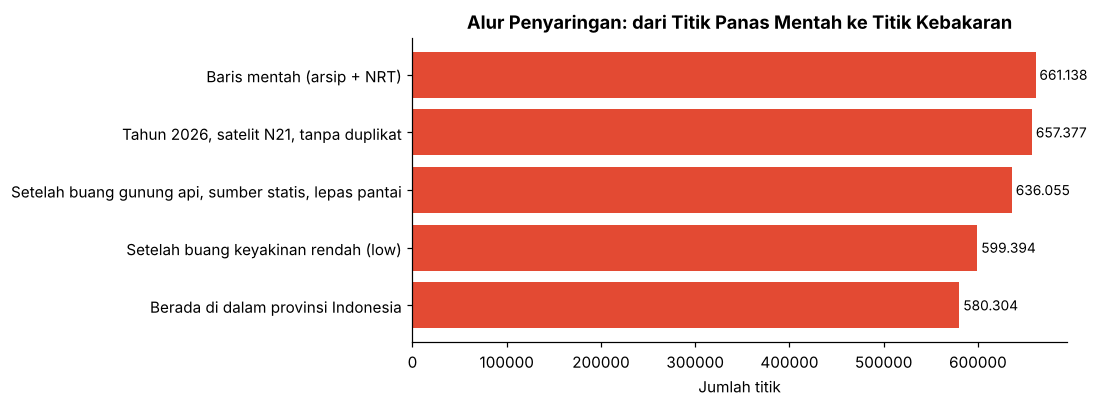

> **Artinya**
>
> Grafik ini merangkum **seluruh proses penyaringan dari awal sampai akhir**, seperti saringan bertingkat: tiap tahap membuang jenis titik yang tidak diinginkan.
>
> Dari **661.138** baris mentah, yang akhirnya dipakai sebagai **titik kebakaran** adalah **580.304** titik (87,8% dari data mentah). Tahap pertama hanya membuang data tahun 2025 (di luar tahun analisis). Tahap berikutnya membuang gunung api, sumber panas statis, deteksi lepas pantai, titik berkeyakinan rendah, dan titik di luar wilayah provinsi Indonesia. Penyaringan yang paling banyak membuang titik adalah tahap **Setelah buang keyakinan rendah (low)** (36.661 titik). Kolom terakhir pada tabel memuat jumlah yang dibuang di tiap tahap.

In [17]:
tf = pd.DataFrame(FUNNEL, columns=["Tahap penyaringan", "Jumlah titik"])
tf["% dari data mentah"] = (tf["Jumlah titik"] / tf["Jumlah titik"].iloc[0] * 100).round(1)
tf["Dibuang di tahap ini"] = (-tf["Jumlah titik"].diff()).fillna(0).astype(int)
display(tf)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(tf["Tahap penyaringan"][::-1], tf["Jumlah titik"][::-1], color="#e34a33")
for i, v in enumerate(tf["Jumlah titik"][::-1]):
    ax.text(v, i, " " + angka(v), va="center", fontsize=9)
ax.set_xlabel("Jumlah titik")
ax.set_title("Alur Penyaringan: dari Titik Panas Mentah ke Titik Kebakaran", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

jelaskan(
    "Grafik ini merangkum **seluruh proses penyaringan dari awal sampai akhir**, seperti saringan bertingkat: tiap tahap membuang jenis titik yang tidak diinginkan.\n\n"
    f"Dari **{angka(tf['Jumlah titik'].iloc[0])}** baris mentah, yang akhirnya dipakai sebagai **titik kebakaran** adalah **{angka(tf['Jumlah titik'].iloc[-1])}** titik "
    f"({pct(tf['Jumlah titik'].iloc[-1] / tf['Jumlah titik'].iloc[0])} dari data mentah). "
    "Tahap pertama hanya membuang data tahun 2025 (di luar tahun analisis). Tahap berikutnya membuang gunung api, sumber panas statis, deteksi lepas pantai, "
    "titik berkeyakinan rendah, dan titik di luar wilayah provinsi Indonesia. "
    f"Penyaringan yang paling banyak membuang titik adalah tahap **{tf['Tahap penyaringan'].iloc[1:].where(tf['Dibuang di tahap ini'].iloc[1:] == tf['Dibuang di tahap ini'].iloc[1:].max()).dropna().iloc[0]}** "
    f"({angka(int(tf['Dibuang di tahap ini'].iloc[1:].max()))} titik). Kolom terakhir pada tabel memuat jumlah yang dibuang di tiap tahap."
)

In [18]:
agregat = (
    titik_ina.groupby("PROVINSI")
    .agg(jumlah_titik=("frp", "size"),
         frp_rata2=("frp", "mean"),
         frp_maks=("frp", "max"),
         frp_total=("frp", "sum"))
    .reset_index()
)

prov_agg = prov.merge(agregat, on="PROVINSI", how="left")
for c in ["jumlah_titik", "frp_total"]:
    prov_agg[c] = prov_agg[c].fillna(0)
prov_agg["jumlah_titik"] = prov_agg["jumlah_titik"].astype(int)

n_nol = int((prov_agg["jumlah_titik"] == 0).sum())
print("Total titik setelah agregasi :", int(prov_agg["jumlah_titik"].sum()),
      "(harus sama dengan jumlah titik di dalam provinsi)")
print("Provinsi tanpa titik kebakaran     :", n_nol, "dari", len(prov_agg))

jelaskan(
    "Titik-titik tadi sekarang **dihitung per provinsi**, seperti menghitung jumlah suara di tiap daerah pemilihan.\n\n"
    f"Totalnya {angka(int(prov_agg['jumlah_titik'].sum()))} titik, sama dengan jumlah titik di dalam Indonesia (artinya tidak ada yang hilang atau terhitung dua kali). "
    + (f"**{n_nol} dari {len(prov_agg)} provinsi tidak memiliki titik kebakaran** pada periode ini." if n_nol > 0
       else "**Semua provinsi memiliki setidaknya satu titik kebakaran** pada periode ini.")
)

Total titik setelah agregasi : 580304 (harus sama dengan jumlah titik di dalam provinsi)
Provinsi tanpa titik kebakaran     : 0 dari 38


> **Artinya**
>
> Titik-titik tadi sekarang **dihitung per provinsi**, seperti menghitung jumlah suara di tiap daerah pemilihan.
>
> Totalnya 580.304 titik, sama dengan jumlah titik di dalam Indonesia (artinya tidak ada yang hilang atau terhitung dua kali). **Semua provinsi memiliki setidaknya satu titik kebakaran** pada periode ini.

### 3.1 Kepadatan titik kebakaran (dihitung dengan CRS equal-area)
Provinsi yang luas wajar punya titik lebih banyak. Agar adil, dihitung juga **kepadatan** = jumlah titik per 10.000 km².

In [19]:
prov_agg["luas_km2"] = prov_agg.to_crs("EPSG:6933").area / 1e6
prov_agg["titik_per_10rbkm2"] = prov_agg["jumlah_titik"] / prov_agg["luas_km2"] * 10_000

tabel = (
    prov_agg.drop(columns="geometry")
    .sort_values("jumlah_titik", ascending=False)
    [["PROVINSI", "jumlah_titik", "luas_km2", "titik_per_10rbkm2", "frp_rata2", "frp_maks"]]
    .rename(columns={
        "PROVINSI": "Provinsi", "jumlah_titik": "Jumlah titik", "luas_km2": "Luas (km²)",
        "titik_per_10rbkm2": "Titik / 10.000 km²", "frp_rata2": "FRP rata-rata (MW)", "frp_maks": "FRP maks (MW)",
    })
    .reset_index(drop=True)
)
tabel.index += 1
print("10 provinsi dengan titik kebakaran terbanyak:")
display(tabel.head(10))

t1 = tabel.iloc[0]
dens = prov_agg.sort_values("titik_per_10rbkm2", ascending=False).iloc[0]
jelaskan(
    "Tabel diurutkan dari provinsi dengan titik kebakaran terbanyak. Cara membaca kolomnya:\n\n"
    "- **Jumlah titik**: banyaknya titik kebakaran di provinsi itu.\n"
    "- **Titik / 10.000 km²**: kepadatan, yaitu berapa titik per area seluas 10.000 km² (sekitar 1,7 kali luas Pulau Bali). Pakai angka ini untuk membandingkan antarprovinsi.\n"
    "- **FRP rata-rata / maks**: seberapa besar rata-rata api dan api terbesar di provinsi itu (megawatt).\n\n"
    f"Provinsi terbanyak adalah **{t1['Provinsi']}** dengan **{angka(t1['Jumlah titik'])} titik** "
    f"({pct(t1['Jumlah titik'] / len(titik_ina))} dari seluruh titik di Indonesia). "
    f"Kalau luas wilayah diperhitungkan, provinsi yang paling 'padat' titik kebakarannya adalah **{dens['PROVINSI']}** "
    f"({angka(dens['titik_per_10rbkm2'], 1)} titik per 10.000 km²). "
    "Luas provinsi dihitung dari poligon yang disederhanakan, jadi angkanya perkiraan."
)

10 provinsi dengan titik kebakaran terbanyak:


,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Kalimantan Tengah,167131,"153,596.08","10,881.20",8.05,792.28
2,Kalimantan Barat,78035,"147,069.33","5,306.00",10.30,515.98
3,Papua Selatan,77161,"116,552.22","6,620.29",8.93,527.25
4,Sumatera Selatan,50807,"87,162.99","5,828.97",8.70,436.55
5,Kalimantan Timur,30709,"124,964.65","2,457.42",7.74,376.26
6,Kalimantan Selatan,23892,"36,697.32","6,510.56",7.87,649.88
7,Maluku,16963,"41,853.15","4,052.98",6.14,326.78
8,Papua Barat,13063,"57,863.33","2,257.56",5.07,237.58
9,Nusa Tenggara Timur,12738,"46,303.45","2,750.98",7.78,373.36
10,Sulawesi Tengah,10975,"59,562.56","1,842.60",8.09,294.98


> **Artinya**
>
> Tabel diurutkan dari provinsi dengan titik kebakaran terbanyak. Cara membaca kolomnya:
>
> - **Jumlah titik**: banyaknya titik kebakaran di provinsi itu.
> - **Titik / 10.000 km²**: kepadatan, yaitu berapa titik per area seluas 10.000 km² (sekitar 1,7 kali luas Pulau Bali). Pakai angka ini untuk membandingkan antarprovinsi.
> - **FRP rata-rata / maks**: seberapa besar rata-rata api dan api terbesar di provinsi itu (megawatt).
>
> Provinsi terbanyak adalah **Kalimantan Tengah** dengan **167.131 titik** (28,8% dari seluruh titik di Indonesia). Kalau luas wilayah diperhitungkan, provinsi yang paling 'padat' titik kebakarannya adalah **Kalimantan Tengah** (10.881,2 titik per 10.000 km²). Luas provinsi dihitung dari poligon yang disederhanakan, jadi angkanya perkiraan.

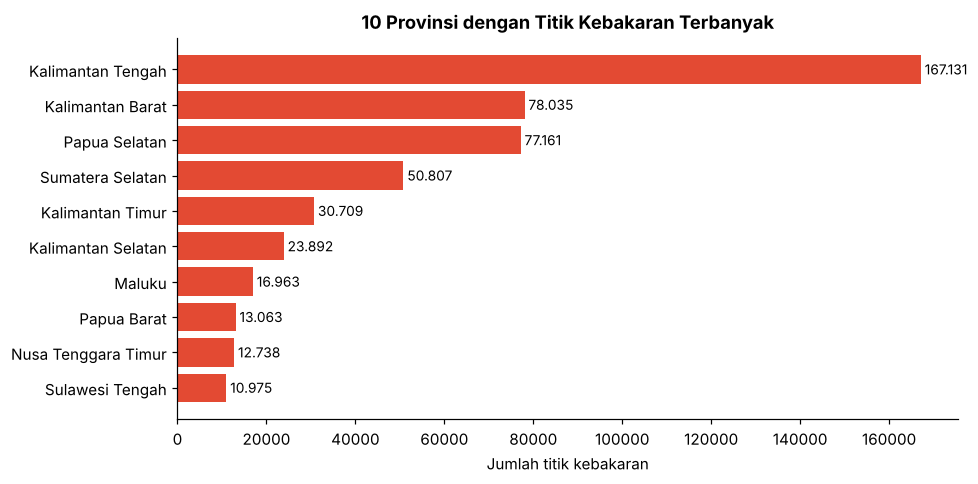

> **Artinya**
>
> Grafik batang ini adalah versi gambar dari tabel di atas: **makin panjang batang, makin banyak titik kebakarannya**.
>
> Tiga provinsi teratas (Kalimantan Tengah, Kalimantan Barat, Papua Selatan) menyumbang **55,5%** dari seluruh titik kebakaran di Indonesia. Artinya titik kebakaran **terkonsentrasi** di beberapa provinsi saja, tidak menyebar merata.

In [20]:
top10 = tabel.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top10["Provinsi"], top10["Jumlah titik"], color="#e34a33")
for i, v in enumerate(top10["Jumlah titik"]):
    ax.text(v, i, " " + angka(v), va="center", fontsize=9)
ax.set_xlabel("Jumlah titik kebakaran")
ax.set_title("10 Provinsi dengan Titik Kebakaran Terbanyak", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

tiga = tabel.head(3)["Jumlah titik"].sum()
jelaskan(
    "Grafik batang ini adalah versi gambar dari tabel di atas: **makin panjang batang, makin banyak titik kebakarannya**.\n\n"
    f"Tiga provinsi teratas ({', '.join(tabel.head(3)['Provinsi'])}) menyumbang **{pct(tiga / len(titik_ina))}** dari seluruh titik kebakaran di Indonesia. "
    + ("Artinya titik kebakaran **terkonsentrasi** di beberapa provinsi saja, tidak menyebar merata." if tiga / len(titik_ina) > 0.4
       else "Artinya titik kebakaran **cukup menyebar** ke banyak provinsi.")
)

---
## 4. Tren waktu (harian dan bulanan)
Karena data mencakup banyak hari, bisa dilihat **kapan** titik kebakaran paling banyak muncul. Ini informasi yang tidak bisa didapat dari data satu hari.

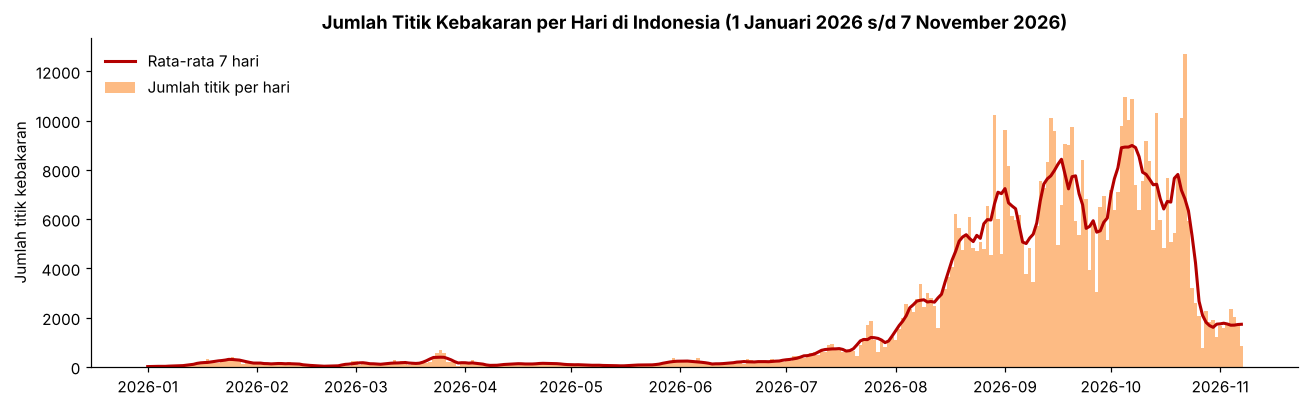

> **Artinya**
>
> Setiap batang adalah **jumlah titik kebakaran dalam satu hari**. Garis merah tua adalah rata-rata 7 hari, supaya naik-turun harian yang acak (misalnya karena awan menutupi satelit) tidak mengaburkan pola besarnya.
>
> Rata-rata ada **1.865,9 titik per hari**. Hari paling banyak adalah **22 Oktober 2026** dengan **12.719 titik**; hari paling sedikit 3 titik. Lonjakan tinggi yang berlangsung beberapa hari berturut-turut biasanya menandakan periode rawan kebakaran.

In [21]:
ti = titik_ina.copy()
ti["tanggal"] = ti["acq_date"].dt.normalize()
ti["bulan"] = ti["acq_date"].dt.to_period("M")

rentang = pd.date_range(tgl_min, tgl_max)
harian = ti.groupby("tanggal").size().reindex(rentang, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(harian.index, harian.values, color="#fdbb84", width=1.0, label="Jumlah titik per hari")
if len(harian) >= 7:
    ax.plot(harian.index, harian.rolling(7, center=True, min_periods=1).mean(),
            color="#b30000", lw=2, label="Rata-rata 7 hari")
ax.set_ylabel("Jumlah titik kebakaran")
ax.set_title(f"Jumlah Titik Kebakaran per Hari di Indonesia ({PERIODE})", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

hari_puncak = harian.idxmax()
jelaskan(
    "Setiap batang adalah **jumlah titik kebakaran dalam satu hari**. Garis merah tua adalah rata-rata 7 hari, supaya naik-turun harian yang "
    "acak (misalnya karena awan menutupi satelit) tidak mengaburkan pola besarnya.\n\n"
    f"Rata-rata ada **{angka(harian.mean(), 1)} titik per hari**. Hari paling banyak adalah **{tgl_id(hari_puncak)}** dengan **{angka(int(harian.max()))} titik**; "
    f"hari paling sedikit {angka(int(harian.min()))} titik. "
    "Lonjakan tinggi yang berlangsung beberapa hari berturut-turut biasanya menandakan periode rawan kebakaran."
)

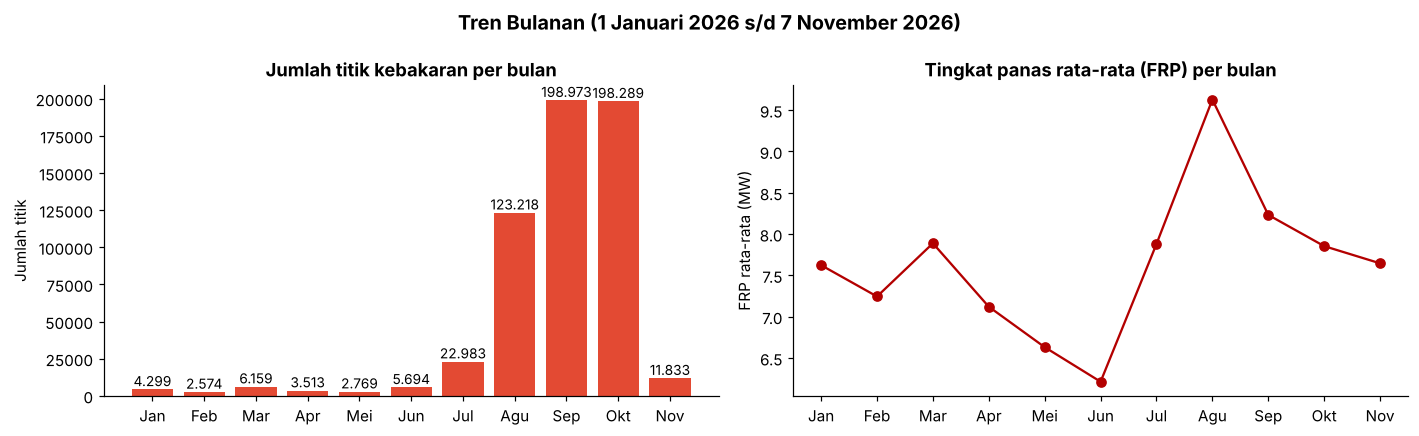

> **Artinya**
>
> **Grafik kiri**: tinggi batang = jumlah titik kebakaran dalam sebulan. **Grafik kanan**: seberapa besar api rata-rata di bulan itu (naik berarti apinya cenderung lebih besar, bukan hanya lebih banyak).
>
> Bulan terbanyak adalah **September** (198.973 titik), dan yang paling sedikit **Februari** (2.574 titik). Jadi bulan puncak sekitar 77,3 kali lipat bulan terendah. Perhatikan bahwa data bulan **November** baru sampai tanggal 7, sehingga batangnya lebih pendek karena belum satu bulan penuh, bukan karena apinya berkurang.

In [22]:
bulan_idx = pd.period_range(tgl_min.to_period("M"), tgl_max.to_period("M"), freq="M")
bulanan = (ti.groupby("bulan").agg(jumlah=("frp", "size"), frp_rata2=("frp", "mean"))
           .reindex(bulan_idx))
bulanan["jumlah"] = bulanan["jumlah"].fillna(0).astype(int)
label_bln = [BULAN_PENDEK[p.month - 1] for p in bulan_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(label_bln, bulanan["jumlah"], color="#e34a33")
for i, v in enumerate(bulanan["jumlah"]):
    axes[0].text(i, v, angka(v), ha="center", va="bottom", fontsize=9)
axes[0].set_title("Jumlah titik kebakaran per bulan", fontweight="bold")
axes[0].set_ylabel("Jumlah titik")

axes[1].plot(label_bln, bulanan["frp_rata2"], marker="o", color="#b30000")
axes[1].set_title("Tingkat panas rata-rata (FRP) per bulan", fontweight="bold")
axes[1].set_ylabel("FRP rata-rata (MW)")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.suptitle(f"Tren Bulanan ({PERIODE})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

puncak = bulanan["jumlah"].idxmax()
terendah = bulanan["jumlah"].idxmin()
bulan_terakhir_penuh = tgl_max.day == tgl_max.days_in_month
teks = (
    "**Grafik kiri**: tinggi batang = jumlah titik kebakaran dalam sebulan. **Grafik kanan**: seberapa besar api rata-rata di bulan itu "
    "(naik berarti apinya cenderung lebih besar, bukan hanya lebih banyak).\n\n"
)
if len(bulanan) > 1:
    teks += (f"Bulan terbanyak adalah **{BULAN[puncak.month - 1]}** ({angka(int(bulanan.loc[puncak, 'jumlah']))} titik), "
             f"dan yang paling sedikit **{BULAN[terendah.month - 1]}** ({angka(int(bulanan.loc[terendah, 'jumlah']))} titik). ")
    if bulanan.loc[terendah, "jumlah"] > 0:
        teks += f"Jadi bulan puncak sekitar {angka(bulanan.loc[puncak, 'jumlah'] / bulanan.loc[terendah, 'jumlah'], 1)} kali lipat bulan terendah. "
    if not bulan_terakhir_penuh:
        teks += (f"Perhatikan bahwa data bulan **{BULAN[tgl_max.month - 1]}** baru sampai tanggal {tgl_max.day}, "
                 "sehingga batangnya lebih pendek karena belum satu bulan penuh, bukan karena apinya berkurang.")
else:
    teks += f"Data hanya mencakup satu bulan ({BULAN[puncak.month - 1]}), jadi belum bisa dibandingkan antarbulan."
jelaskan(teks)

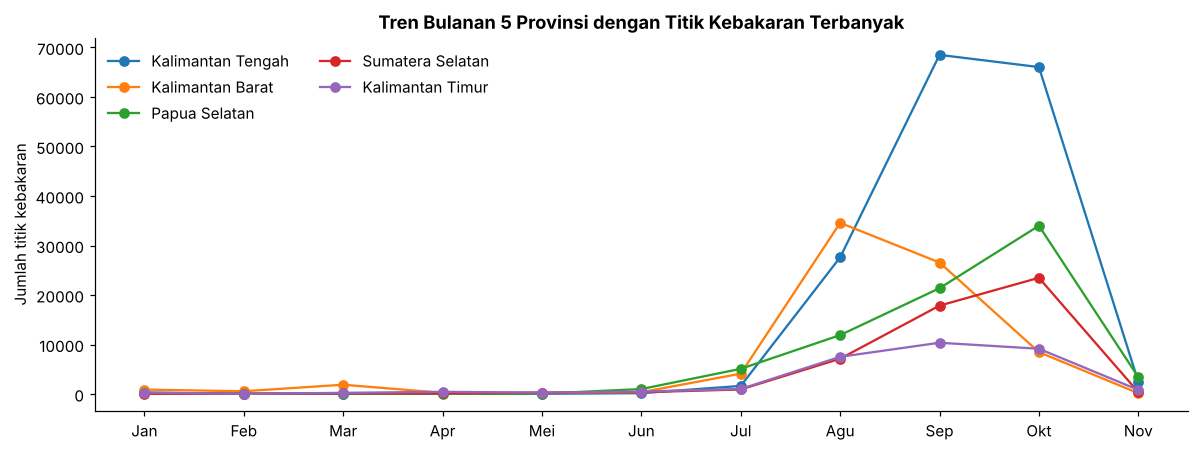

> **Artinya**
>
> Setiap garis mewakili satu provinsi, menunjukkan **naik-turunnya jumlah titik kebakaran dari bulan ke bulan**. Dengan ini terlihat provinsi mana yang 'musimnya' berbeda.
>
> Bulan puncak tiap provinsi: **Kalimantan Tengah** (September); **Kalimantan Barat** (Agustus); **Papua Selatan** (Oktober); **Sumatera Selatan** (Oktober); **Kalimantan Timur** (September). Provinsi yang puncaknya berbeda bulan menandakan pola musim kemarau yang tidak sama di tiap wilayah.

In [23]:
top5 = ti["PROVINSI"].value_counts().head(5).index.tolist()
pivot = (ti[ti["PROVINSI"].isin(top5)].groupby(["bulan", "PROVINSI"]).size().unstack(fill_value=0)
         .reindex(index=bulan_idx, columns=top5, fill_value=0))

fig, ax = plt.subplots(figsize=(11, 4.2))
for p in top5:
    ax.plot(label_bln, pivot[p], marker="o", label=p)
ax.set_ylabel("Jumlah titik kebakaran")
ax.set_title("Tren Bulanan 5 Provinsi dengan Titik Kebakaran Terbanyak", fontweight="bold")
ax.legend(frameon=False, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

teks = ("Setiap garis mewakili satu provinsi, menunjukkan **naik-turunnya jumlah titik kebakaran dari bulan ke bulan**. "
        "Dengan ini terlihat provinsi mana yang 'musimnya' berbeda.\n\n")
if len(bulan_idx) > 1:
    puncak_prov = {p: BULAN[pivot[p].idxmax().month - 1] for p in top5}
    teks += "Bulan puncak tiap provinsi: " + "; ".join(f"**{p}** ({b})" for p, b in puncak_prov.items()) + ". "
    teks += ("Provinsi yang puncaknya berbeda bulan menandakan pola musim kemarau yang tidak sama di tiap wilayah."
             if len(set(puncak_prov.values())) > 1 else "Kelimanya memuncak pada bulan yang sama, jadi pola musimnya mirip.")
else:
    teks += "Data hanya satu bulan, jadi garis tidak menunjukkan perubahan."
jelaskan(teks)

---
## 5. Peta choropleth dan peta tingkat panas

### 5.1 Pemilihan kelas warna
Sebaran jumlah titik biasanya **sangat timpang**: beberapa provinsi punya jauh lebih banyak titik dibanding yang lain. Jika dibagi rata (*equal interval*), hampir semua provinsi tampak sama pucatnya. Karena itu kelas warna ditentukan dengan metode **Natural Breaks** (mengelompokkan provinsi yang angkanya berdekatan) agar perbedaan antarprovinsi tetap terlihat. Provinsi **tanpa titik kebakaran** (nilai 0), jika ada, dijadikan kelas tersendiri berwarna paling pucat. Batas kelas dihitung otomatis dari data.

In [24]:
def buat_kelas(nilai, k=5):
    nilai = pd.Series(nilai)
    nz = nilai[nilai > 0]
    ada_nol = bool((nilai == 0).any())
    if nz.empty:
        return [0], ["0 (tidak ada)"]
    k = int(min(k, nz.nunique()))
    if k <= 1:
        tepi = [int(nz.max())]
    else:
        nb_ = mapclassify.NaturalBreaks(nz.values, k=k)
        tepi = sorted(set(int(round(b)) for b in nb_.bins))
    tepi[-1] = int(nz.max())
    bins_ = ([0] if ada_nol else []) + tepi
    labels_ = ["0 (tidak ada)"] if ada_nol else []
    lo = 1 if ada_nol else int(nz.min())
    for t in tepi:
        labels_.append(f"{lo} - {t}" if lo < t else f"{t}")
        lo = t + 1
    return bins_, labels_


bins, label_kelas = buat_kelas(prov_agg["jumlah_titik"])
print("Batas kelas :", bins)
print("Label kelas :", label_kelas)


def rapikan_legenda(ax):
    # ganti label legenda otomatis (mis. '0, 5') dengan label yang mudah dibaca
    for teks_, lab in zip(ax.get_legend().get_texts(), label_kelas):
        teks_.set_text(lab)


kls = pd.cut(prov_agg["jumlah_titik"], bins=[-1] + bins, labels=label_kelas, ordered=False)
tab_kelas = kls.value_counts().reindex(label_kelas).rename("jumlah provinsi").to_frame()
display(tab_kelas)

jelaskan(
    "Provinsi dikelompokkan ke dalam beberapa **kelas warna** menurut jumlah titik kebakarannya. Tabel ini menunjukkan berapa provinsi masuk tiap kelas.\n\n"
    f"Pada data ini, kelas terendah ({label_kelas[0]}) berisi **{int(tab_kelas.iloc[0, 0])} provinsi**, sedangkan kelas tertinggi ({label_kelas[-1]}) hanya berisi "
    f"**{int(tab_kelas.iloc[-1, 0])} provinsi**. "
    + ("Selisih jumlah provinsi yang besar antarkelas menandakan titik kebakaran **tidak tersebar merata**. " if tab_kelas.iloc[0, 0] > tab_kelas.iloc[-1, 0]
       else "Jumlah provinsi cukup seimbang di tiap kelas. ")
    + "Warna yang makin gelap pada peta berikutnya berarti kelas dengan titik kebakaran makin banyak."
)

Batas kelas : [8428, 30709, 50807, 78035, 167131]
Label kelas : ['27 - 8428', '8429 - 30709', '30710 - 50807', '50808 - 78035', '78036 - 167131']


,jumlah provinsi
jumlah_titik,
27 - 8428,28
8429 - 30709,6
30710 - 50807,1
50808 - 78035,2
78036 - 167131,1


> **Artinya**
>
> Provinsi dikelompokkan ke dalam beberapa **kelas warna** menurut jumlah titik kebakarannya. Tabel ini menunjukkan berapa provinsi masuk tiap kelas.
>
> Pada data ini, kelas terendah (27 - 8428) berisi **28 provinsi**, sedangkan kelas tertinggi (78036 - 167131) hanya berisi **1 provinsi**. Selisih jumlah provinsi yang besar antarkelas menandakan titik kebakaran **tidak tersebar merata**. Warna yang makin gelap pada peta berikutnya berarti kelas dengan titik kebakaran makin banyak.

In [25]:
n_t = len(titik_ina)
UKURAN, ALPHA, TEPI = (9, 0.9, 0.15) if n_t < 3000 else ((4, 0.6, 0) if n_t < 30000 else ((1.5, 0.5, 0) if n_t < 300000 else (0.6, 0.35, 0)))
VMAX_FRP = titik_ina["frp"].quantile(0.95)
print(f"Jumlah titik digambar: {angka(n_t)} | ukuran titik: {UKURAN} | batas atas warna FRP (persentil 95): {VMAX_FRP:.1f} MW")

Jumlah titik digambar: 580.304 | ukuran titik: 0.6 | batas atas warna FRP (persentil 95): 25.7 MW


### 5.2 Peta 1 — Choropleth jumlah titik kebakaran per provinsi

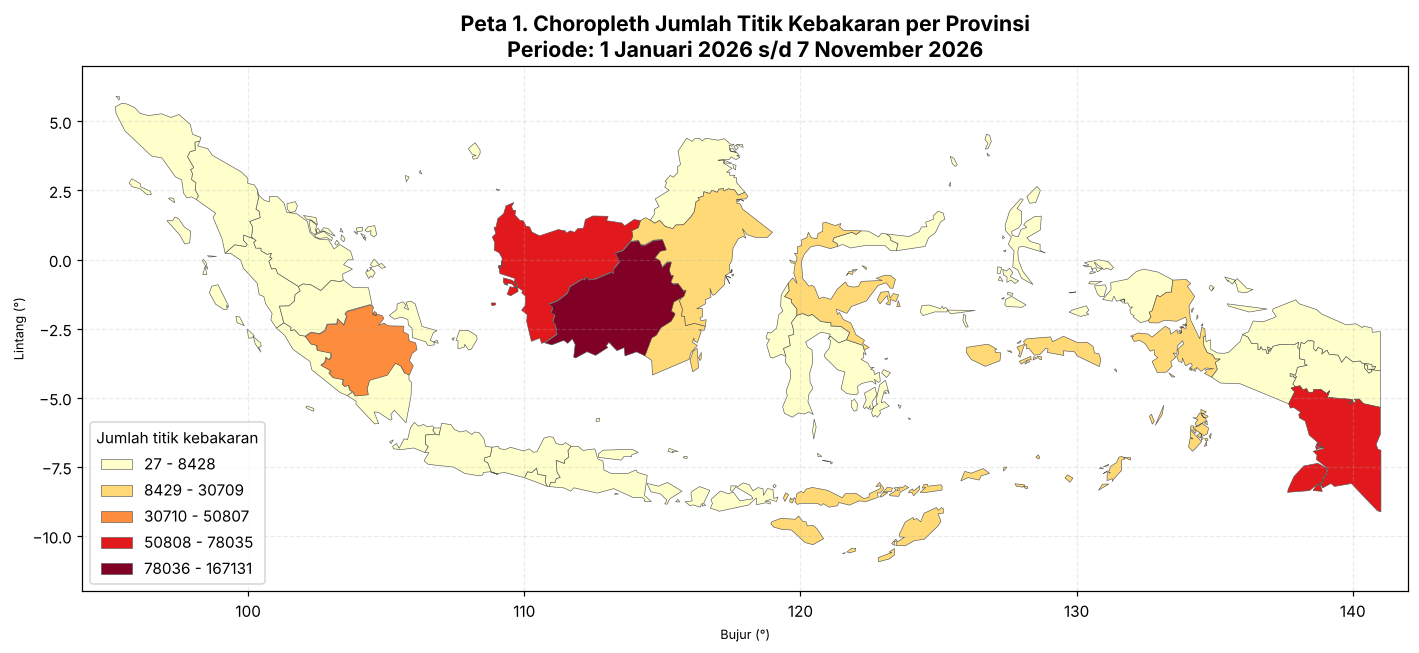

> **Artinya**
>
> Ini peta **choropleth**: tiap provinsi diwarnai menurut banyaknya titik kebakaran. **Makin gelap/merah = makin banyak titik kebakaran**; warna paling pucat = tidak ada atau sedikit. Legenda di kiri bawah menunjukkan arti tiap warna.
>
> Provinsi berwarna paling gelap adalah **Kalimantan Tengah** (167.131 titik), disusul Kalimantan Barat (78.035) dan Papua Selatan (77.161). Peta ini menjawab pertanyaan: **di provinsi mana titik kebakaran paling banyak?**

In [26]:
fig, ax = plt.subplots(figsize=(13, 6))

prov_agg.plot(
    column="jumlah_titik", cmap="YlOrRd",
    scheme="UserDefined", classification_kwds={"bins": bins},
    edgecolor="#555555", linewidth=0.4, ax=ax,
    legend=True,
    legend_kwds={"title": "Jumlah titik kebakaran", "loc": "lower left", "frameon": True},
)
rapikan_legenda(ax)
ax.set_xlim(94, 142); ax.set_ylim(-12, 7)
ax.set_title(f"Peta 1. Choropleth Jumlah Titik Kebakaran per Provinsi\nPeriode: {PERIODE}", fontsize=14, fontweight="bold")
ax.set_xlabel("Bujur (°)"); ax.set_ylabel("Lintang (°)")
ax.grid(alpha=0.25, linestyle="--")
plt.tight_layout()
plt.show()

urut_p = prov_agg.sort_values("jumlah_titik", ascending=False)
jelaskan(
    "Ini peta **choropleth**: tiap provinsi diwarnai menurut banyaknya titik kebakaran. **Makin gelap/merah = makin banyak titik kebakaran**; "
    "warna paling pucat = tidak ada atau sedikit. Legenda di kiri bawah menunjukkan arti tiap warna.\n\n"
    f"Provinsi berwarna paling gelap adalah **{urut_p.iloc[0]['PROVINSI']}** ({angka(int(urut_p.iloc[0]['jumlah_titik']))} titik), "
    f"disusul {urut_p.iloc[1]['PROVINSI']} ({angka(int(urut_p.iloc[1]['jumlah_titik']))}) dan {urut_p.iloc[2]['PROVINSI']} ({angka(int(urut_p.iloc[2]['jumlah_titik']))}). "
    "Peta ini menjawab pertanyaan: **di provinsi mana titik kebakaran paling banyak?**"
)

### 5.3 Peta 2 — Tingkat panas tiap titik (FRP)
Warna titik mengikuti nilai **FRP** (*Fire Radiative Power*). Warna dibatasi pada persentil 95 agar beberapa titik ekstrem tidak membuat seluruh titik lain tampak seragam.

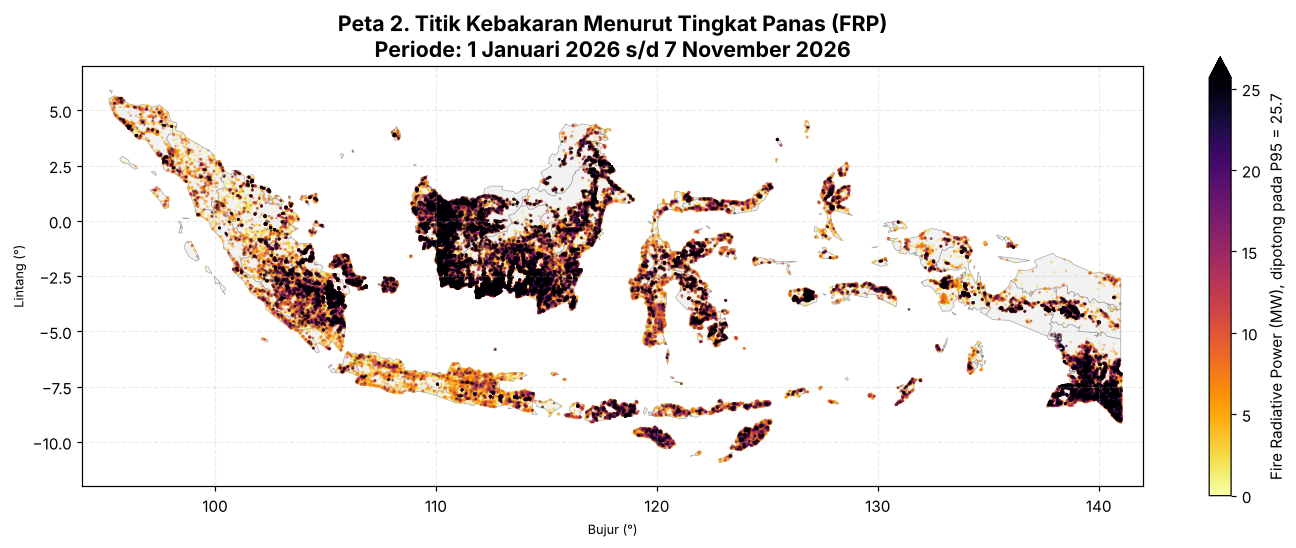

> **Artinya**
>
> Setiap **titik** di peta adalah satu titik kebakaran. **Warnanya menunjukkan seberapa besar/panas api tersebut**: kuning muda = api kecil, oranye-merah = sedang, **hitam/merah sangat tua = api paling besar** (lihat batang warna di kanan, satuan megawatt).
>
> Titik terbesar tercatat 792,3 MW di Kalimantan Tengah. Wilayah yang titiknya **padat dan bercampur warna gelap** adalah area yang paling perlu diwaspadai: banyak api sekaligus ada yang besar. Peta ini menjawab pertanyaan: **seberapa panas titik kebakaran di tiap lokasi?**

In [27]:
fig, ax = plt.subplots(figsize=(13, 6))
prov_agg.plot(ax=ax, color="#f2f2f2", edgecolor="#999999", linewidth=0.4)

titik_ina.sort_values("frp").plot(
    ax=ax, column="frp", cmap="inferno_r", markersize=UKURAN, alpha=ALPHA,
    vmin=0, vmax=VMAX_FRP, legend=True,
    legend_kwds={"label": f"Fire Radiative Power (MW), dipotong pada P95 = {VMAX_FRP:.1f}", "shrink": 0.7},
)
ax.set_xlim(94, 142); ax.set_ylim(-12, 7)
ax.set_title(f"Peta 2. Titik Kebakaran Menurut Tingkat Panas (FRP)\nPeriode: {PERIODE}", fontsize=14, fontweight="bold")
ax.set_xlabel("Bujur (°)"); ax.set_ylabel("Lintang (°)")
ax.grid(alpha=0.25, linestyle="--")
plt.tight_layout()
plt.show()

jelaskan(
    "Setiap **titik** di peta adalah satu titik kebakaran. **Warnanya menunjukkan seberapa besar/panas api tersebut**: "
    "kuning muda = api kecil, oranye-merah = sedang, **hitam/merah sangat tua = api paling besar** (lihat batang warna di kanan, satuan megawatt).\n\n"
    f"Titik terbesar tercatat {angka(titik_ina['frp'].max(), 1)} MW di {titik_ina.loc[titik_ina['frp'].idxmax(), 'PROVINSI']}. "
    "Wilayah yang titiknya **padat dan bercampur warna gelap** adalah area yang paling perlu diwaspadai: banyak api sekaligus ada yang besar. "
    "Peta ini menjawab pertanyaan: **seberapa panas titik kebakaran di tiap lokasi?**"
)

---
## 6. Peta akhir lengkap

Peta akhir menggabungkan **choropleth jumlah titik per provinsi** dan **titik berwarna menurut FRP**, dilengkapi: judul dan subjudul, legenda choropleth, colorbar FRP, **north arrow**, **skala**, grid koordinat, serta keterangan sumber data dan CRS.

> **Catatan skala:** peta memakai EPSG:4326 (derajat), sehingga panjang 1° bujur berubah menurut lintang. Skala dihitung pada lintang sekitar 9°LS, jadi bersifat **perkiraan**.

In [28]:
def tambah_north_arrow(ax, x=0.05, y_bawah=0.78, y_atas=0.90):
    # panah utara di koordinat sumbu (0-1)
    ax.annotate("", xy=(x, y_atas), xytext=(x, y_bawah), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color="black", lw=2.2, mutation_scale=22))
    ax.text(x, y_atas + 0.02, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=16, fontweight="bold")


def tambah_skala(ax, km=500, x0=0.70, y0=0.06, lintang=-9):
    # batang skala sederhana (perkiraan pada lintang tertentu)
    derajat = km / (111.32 * np.cos(np.radians(abs(lintang))))
    xmin, xmax = ax.get_xlim(); ymin, ymax = ax.get_ylim()
    x_start = xmin + x0 * (xmax - xmin)
    y = ymin + y0 * (ymax - ymin)
    ax.plot([x_start, x_start + derajat], [y, y], color="black", lw=4, solid_capstyle="butt")
    ax.plot([x_start, x_start + derajat / 2], [y, y], color="white", lw=2, solid_capstyle="butt")
    ax.text(x_start + derajat / 2, y + 0.02 * (ymax - ymin), f"{km} km (perkiraan)", ha="center", fontsize=9)

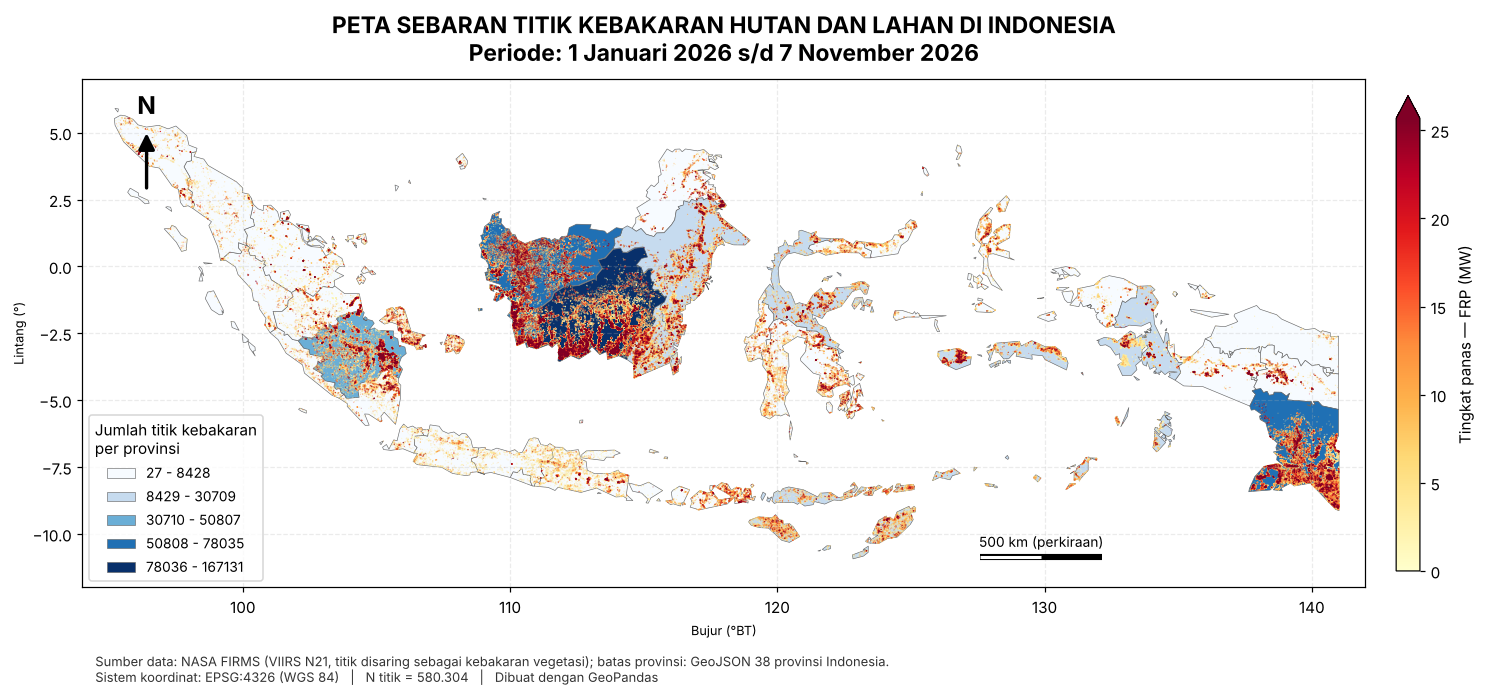

Peta disimpan sebagai peta_titik_kebakaran_indonesia_2026.png


> **Artinya**
>
> Ini **peta utama untuk dikumpulkan**: gabungan dua informasi dalam satu gambar.
>
> - **Warna biru pada provinsi**: banyaknya titik kebakaran di provinsi itu (makin gelap = makin banyak; lihat legenda kiri bawah).
> - **Titik berwarna kuning sampai merah tua**: lokasi tiap titik kebakaran dan seberapa besar apinya (lihat batang warna kanan).
> - **Panah N** menunjukkan arah utara, **batang skala** memberi gambaran jarak, dan **judul** menyebut periode datanya.
>
> Peta menampilkan 580.304 titik kebakaran selama 1 Januari 2026 s/d 7 November 2026. Provinsi biru tua yang juga dipenuhi titik merah adalah area dengan titik kebakaran paling banyak sekaligus paling besar.

In [29]:
fig, ax = plt.subplots(figsize=(15, 7.5))

prov_agg.plot(
    column="jumlah_titik", cmap="Blues",
    scheme="UserDefined", classification_kwds={"bins": bins},
    edgecolor="#666666", linewidth=0.4, ax=ax,
    legend=True,
    legend_kwds={"title": "Jumlah titik kebakaran\nper provinsi", "loc": "lower left",
                 "frameon": True, "fontsize": 9, "title_fontsize": 10},
)
rapikan_legenda(ax)

titik_ina.sort_values("frp").plot(
    ax=ax, column="frp", cmap="YlOrRd", markersize=UKURAN, alpha=ALPHA,
    edgecolor="black", linewidth=TEPI, vmin=0, vmax=VMAX_FRP,
    legend=True,
    legend_kwds={"label": "Tingkat panas — FRP (MW)", "shrink": 0.6, "pad": 0.02},
)

ax.set_xlim(94, 142); ax.set_ylim(-12, 7)
ax.set_title("PETA SEBARAN TITIK KEBAKARAN HUTAN DAN LAHAN DI INDONESIA\n" + f"Periode: {PERIODE}",
             fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Bujur (°BT)"); ax.set_ylabel("Lintang (°)")
ax.grid(alpha=0.25, linestyle="--")

tambah_north_arrow(ax)
tambah_skala(ax, km=500)

ax.text(0.01, -0.13,
        f"Sumber data: NASA FIRMS (VIIRS {SATELIT_PAKAI}, titik disaring sebagai kebakaran vegetasi); batas provinsi: GeoJSON 38 provinsi Indonesia.\n"
        f"Sistem koordinat: EPSG:4326 (WGS 84)   |   N titik = {angka(len(titik_ina))}   |   Dibuat dengan GeoPandas",
        transform=ax.transAxes, fontsize=8.5, va="top", color="#333333")

plt.tight_layout()
plt.savefig("peta_titik_kebakaran_indonesia_2026.png", dpi=300, bbox_inches="tight")
plt.show()
print("Peta disimpan sebagai peta_titik_kebakaran_indonesia_2026.png")

jelaskan(
    "Ini **peta utama untuk dikumpulkan**: gabungan dua informasi dalam satu gambar.\n\n"
    "- **Warna biru pada provinsi**: banyaknya titik kebakaran di provinsi itu (makin gelap = makin banyak; lihat legenda kiri bawah).\n"
    "- **Titik berwarna kuning sampai merah tua**: lokasi tiap titik kebakaran dan seberapa besar apinya (lihat batang warna kanan).\n"
    "- **Panah N** menunjukkan arah utara, **batang skala** memberi gambaran jarak, dan **judul** menyebut periode datanya.\n\n"
    f"Peta menampilkan {angka(len(titik_ina))} titik kebakaran selama {PERIODE}. Provinsi biru tua yang juga dipenuhi titik merah adalah area "
    "dengan titik kebakaran paling banyak sekaligus paling besar."
)

---
## 7. Peta zoom per wilayah

Peta nasional menampilkan seluruh Indonesia sehingga detail di dalam tiap pulau sulit dibaca. Karena itu dibuat **peta yang diperbesar** untuk **tujuh wilayah** yang mencakup seluruh provinsi: **Sumatera, Jawa, Bali dan Nusa Tenggara, Kalimantan, Sulawesi, Maluku, dan Papua**.

**Cara membaca peta wilayah**
- Provinsi di luar wilayah ditampilkan abu-abu sebagai latar.
- Warna **biru** pada provinsi = jumlah titik kebakaran. Skala warna **dihitung ulang per wilayah**, jadi baca angkanya pada colorbar dan label.
- Warna **titik** (kuning ke merah tua) = tingkat panas (FRP). Skala FRP **sama di semua peta** agar antarwilayah bisa dibandingkan.
- Label di tiap provinsi berisi nama provinsi dan jumlah titik kebakarannya.

In [30]:
WILAYAH = {
    "Sumatera": dict(
        provinsi=["Aceh", "Sumatera Utara", "Sumatera Barat", "Riau", "Jambi",
                  "Sumatera Selatan", "Bengkulu", "Lampung",
                  "Kepulauan Bangka Belitung", "Kepulauan Riau"],
        xlim=(94, 110), ylim=(-6.8, 6.4), figsize=(11, 9), skala_km=300),
    "Jawa": dict(
        provinsi=["Banten", "DKI Jakarta", "Jawa Barat", "Jawa Tengah",
                  "Daerah Istimewa Yogyakarta", "Jawa Timur"],
        xlim=(104.5, 115.5), ylim=(-9.2, -5.4), figsize=(13, 6), skala_km=200),
    "Bali dan Nusa Tenggara": dict(
        provinsi=["Bali", "Nusa Tenggara Barat", "Nusa Tenggara Timur"],
        xlim=(114, 127), ylim=(-11.3, -7.6), figsize=(13, 6), skala_km=200),
    "Kalimantan": dict(
        provinsi=["Kalimantan Barat", "Kalimantan Tengah", "Kalimantan Selatan",
                  "Kalimantan Timur", "Kalimantan Utara"],
        xlim=(108, 119.5), ylim=(-4.4, 4.7), figsize=(10, 9), skala_km=200),
    "Sulawesi": dict(
        provinsi=["Sulawesi Utara", "Gorontalo", "Sulawesi Tengah",
                  "Sulawesi Barat", "Sulawesi Selatan", "Sulawesi Tenggara"],
        xlim=(118, 127.5), ylim=(-7.8, 4.8), figsize=(10, 10), skala_km=200),
    "Maluku": dict(
        provinsi=["Maluku", "Maluku Utara"],
        xlim=(123, 135.5), ylim=(-8.9, 3.2), figsize=(11, 10), skala_km=200),
    "Papua": dict(
        provinsi=["Papua", "Papua Barat", "Papua Barat Daya",
                  "Papua Tengah", "Papua Pegunungan", "Papua Selatan"],
        xlim=(129, 141.5), ylim=(-9.5, 1.2), figsize=(12, 8), skala_km=200),
}

# pemeriksaan: semua provinsi di data harus masuk salah satu wilayah
terdaftar = {p for c in WILAYAH.values() for p in c["provinsi"]}
print("Provinsi di data yang belum masuk wilayah mana pun:", sorted(set(prov["PROVINSI"]) - terdaftar) or "tidak ada")
prov_ke_wilayah = {p: w for w, c in WILAYAH.items() for p in c["provinsi"]}
titik_ina["wilayah"] = titik_ina["PROVINSI"].map(prov_ke_wilayah)


def titik_label(geom):
    # titik label di bagian poligon terbesar (provinsi kepulauan punya banyak bagian)
    if geom.geom_type == "MultiPolygon":
        geom = max(geom.geoms, key=lambda g: g.area)
    return geom.representative_point()


def peta_wilayah(nama, cfg):
    daftar = cfg["provinsi"]
    sub = prov_agg[prov_agg["PROVINSI"].isin(daftar)]
    pts = titik_ina[titik_ina["PROVINSI"].isin(daftar)]
    vmax_j = max(sub["jumlah_titik"].max(), 1)

    fig, ax = plt.subplots(figsize=cfg["figsize"])
    prov_agg.plot(ax=ax, color="#eeeeee", edgecolor="#bbbbbb", linewidth=0.3)
    sub.plot(ax=ax, column="jumlah_titik", cmap="Blues", vmin=0, vmax=vmax_j,
             edgecolor="#444444", linewidth=0.6, legend=True,
             legend_kwds={"label": "Jumlah titik kebakaran per provinsi", "shrink": 0.55, "pad": 0.01})
    if len(pts) > 0:
        pts.sort_values("frp").plot(ax=ax, column="frp", cmap="YlOrRd", markersize=UKURAN * 1.8, alpha=ALPHA,
                                    edgecolor="black", linewidth=TEPI, vmin=0, vmax=VMAX_FRP, legend=True,
                                    legend_kwds={"label": "Tingkat panas - FRP (MW)", "shrink": 0.55, "pad": 0.04})
    ax.set_xlim(*cfg["xlim"]); ax.set_ylim(*cfg["ylim"])

    for _, r in sub.iterrows():
        p = titik_label(r.geometry)
        if cfg["xlim"][0] < p.x < cfg["xlim"][1] and cfg["ylim"][0] < p.y < cfg["ylim"][1]:
            ax.annotate(f"{r['PROVINSI']}\n{angka(int(r['jumlah_titik']))} titik", (p.x, p.y),
                        ha="center", va="center", fontsize=8.5, fontweight="bold", color="black",
                        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

    ax.set_title(f"PETA {nama.upper()}: SEBARAN TITIK KEBAKARAN PER PROVINSI\nPeriode: {PERIODE}",
                 fontsize=14, fontweight="bold", pad=10)
    ax.set_xlabel("Bujur (°BT)"); ax.set_ylabel("Lintang (°)")
    ax.grid(alpha=0.25, linestyle="--")
    tambah_north_arrow(ax)
    tambah_skala(ax, km=cfg["skala_km"], x0=0.05, y0=0.05, lintang=(cfg["ylim"][0] + cfg["ylim"][1]) / 2)
    ax.annotate(
        f"Sumber: NASA FIRMS (VIIRS {SATELIT_PAKAI}, disaring sebagai kebakaran vegetasi); batas provinsi: GeoJSON 38 provinsi.   "
        f"CRS: EPSG:4326   |   N titik wilayah = {angka(len(pts))}",
        xy=(0, 0), xycoords="axes fraction", xytext=(0, -42), textcoords="offset points",
        fontsize=8, va="top", color="#333333")
    plt.tight_layout()
    plt.savefig(f"peta_{nama.lower().replace(' ', '_')}_2026.png", dpi=300, bbox_inches="tight")
    plt.show()


def ringkasan_wilayah(nama, cfg):
    daftar = cfg["provinsi"]
    sub = prov_agg[prov_agg["PROVINSI"].isin(daftar)]
    pts = titik_ina[titik_ina["PROVINSI"].isin(daftar)]
    n_wil, n_nas = len(pts), len(titik_ina)

    if n_wil == 0:
        jelaskan(f"Tidak ada titik kebakaran yang tercatat di **{nama}** pada periode {PERIODE}.")
    else:
        top = sub.sort_values("jumlah_titik", ascending=False).iloc[0]
        padat = sub.sort_values("titik_per_10rbkm2", ascending=False).iloc[0]
        panas = pts.loc[pts["frp"].idxmax()]
        nol = int((sub["jumlah_titik"] == 0).sum())
        jelaskan(
            f"Peta di atas memperbesar **{nama}**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.\n\n"
            f"Di {nama} tercatat **{angka(n_wil)} titik kebakaran**, atau **{pct(n_wil / n_nas)}** dari seluruh titik di Indonesia. "
            f"Provinsi terbanyak adalah **{top['PROVINSI']}** ({angka(int(top['jumlah_titik']))} titik, {pct(top['jumlah_titik'] / n_wil)} dari wilayah ini). "
            f"Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **{padat['PROVINSI']}** "
            f"({angka(padat['titik_per_10rbkm2'], 1)} titik per 10.000 km²). "
            + (f"{nol} dari {len(sub)} provinsi di sini tidak punya titik kebakaran. " if nol > 0 else "Semua provinsi di sini punya titik kebakaran. ")
            + f"Rata-rata tingkat panas (FRP) wilayah ini {angka(pts['frp'].mean(), 1)} MW, dibanding {angka(titik_ina['frp'].mean(), 1)} MW secara nasional; "
            f"titik terbesar {angka(panas['frp'], 1)} MW di {panas['PROVINSI']}.\n\n"
            "Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak)."
        )

    tabel_w = (sub.drop(columns="geometry")
               .sort_values("jumlah_titik", ascending=False)
               [["PROVINSI", "jumlah_titik", "luas_km2", "titik_per_10rbkm2", "frp_rata2", "frp_maks"]]
               .rename(columns={"PROVINSI": "Provinsi", "jumlah_titik": "Jumlah titik",
                                "luas_km2": "Luas (km²)", "titik_per_10rbkm2": "Titik / 10.000 km²",
                                "frp_rata2": "FRP rata-rata (MW)", "frp_maks": "FRP maks (MW)"})
               .reset_index(drop=True))
    tabel_w.index += 1
    return tabel_w

Provinsi di data yang belum masuk wilayah mana pun: tidak ada


### 7.1 Sumatera

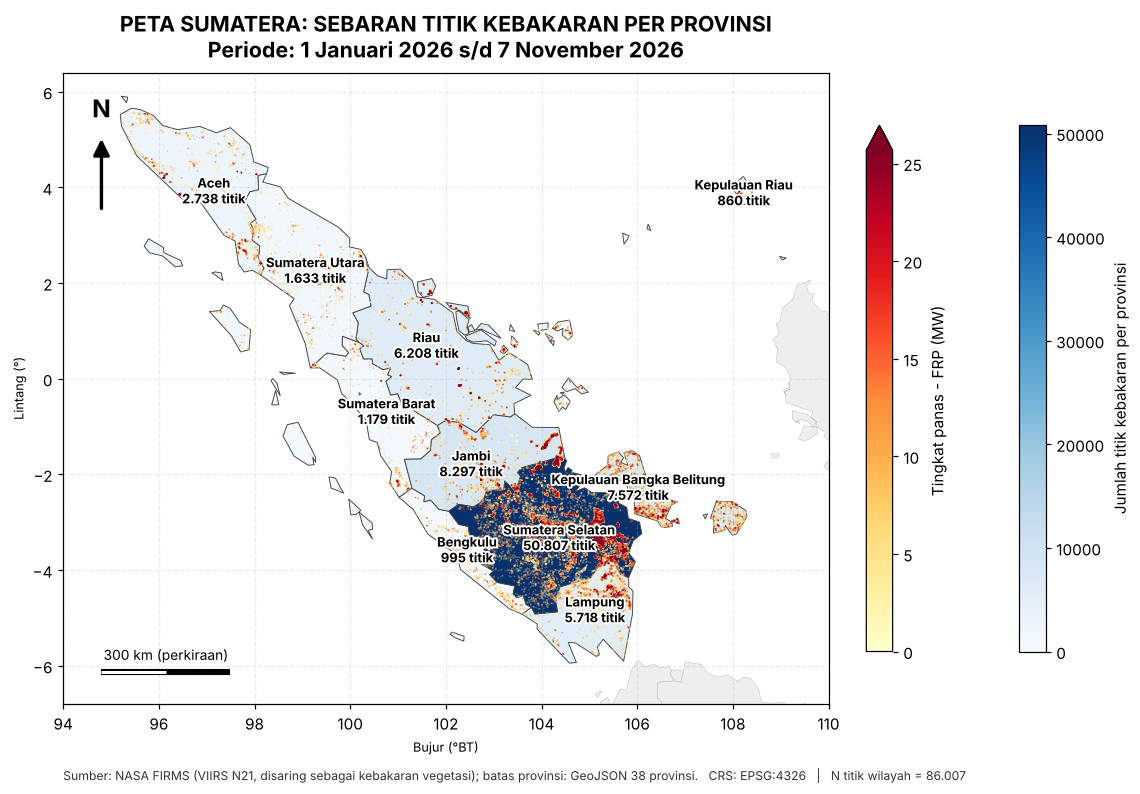

> **Artinya**
>
> Peta di atas memperbesar **Sumatera**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.
>
> Di Sumatera tercatat **86.007 titik kebakaran**, atau **14,8%** dari seluruh titik di Indonesia. Provinsi terbanyak adalah **Sumatera Selatan** (50.807 titik, 59,1% dari wilayah ini). Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **Sumatera Selatan** (5.829,0 titik per 10.000 km²). Semua provinsi di sini punya titik kebakaran. Rata-rata tingkat panas (FRP) wilayah ini 8,5 MW, dibanding 8,3 MW secara nasional; titik terbesar 436,6 MW di Sumatera Selatan.
>
> Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak).

,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Sumatera Selatan,50807,"87,162.99","5,828.97",8.70,436.55
2,Jambi,8297,"49,146.90","1,688.20",7.41,208.07
3,Kepulauan Bangka Belitung,7572,"16,774.06","4,514.11",8.46,335.28
4,Riau,6208,"88,478.55",701.64,7.63,304.90
5,Lampung,5718,"33,468.12","1,708.49",9.17,274.19
6,Aceh,2738,"57,233.35",478.39,8.89,261.97
7,Sumatera Utara,1633,"71,854.96",227.26,7.38,115.99
8,Sumatera Barat,1179,"42,026.65",280.54,7.54,154.33
9,Bengkulu,995,"20,105.65",494.89,7.34,85.25
10,Kepulauan Riau,860,"5,785.28","1,486.53",8.36,276.15


In [31]:
peta_wilayah("Sumatera", WILAYAH["Sumatera"])
ringkasan_wilayah("Sumatera", WILAYAH["Sumatera"])

### 7.2 Jawa

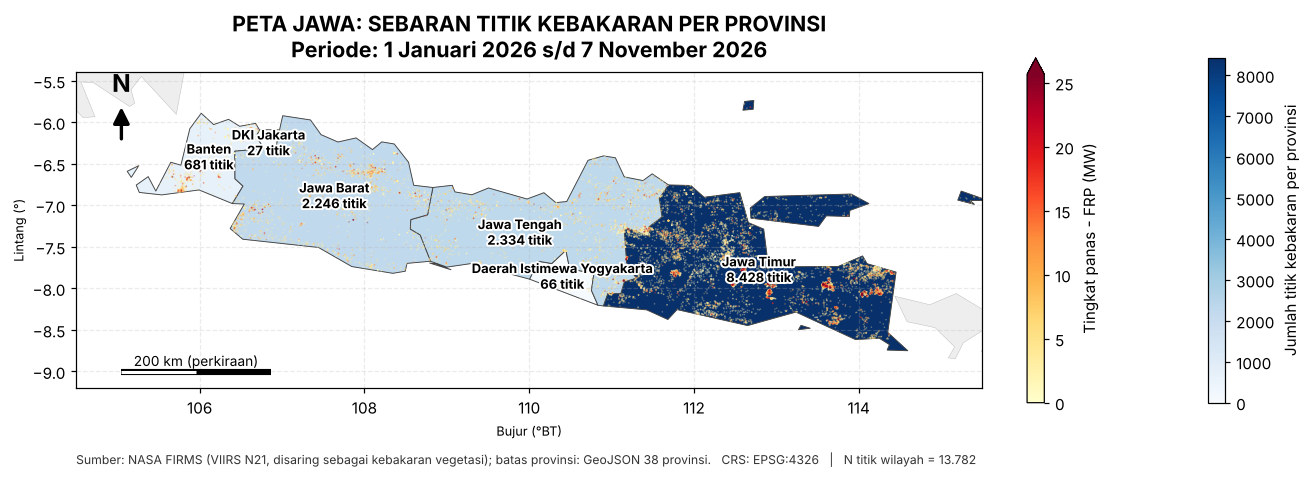

> **Artinya**
>
> Peta di atas memperbesar **Jawa**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.
>
> Di Jawa tercatat **13.782 titik kebakaran**, atau **2,4%** dari seluruh titik di Indonesia. Provinsi terbanyak adalah **Jawa Timur** (8.428 titik, 61,2% dari wilayah ini). Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **Jawa Timur** (1.770,7 titik per 10.000 km²). Semua provinsi di sini punya titik kebakaran. Rata-rata tingkat panas (FRP) wilayah ini 5,6 MW, dibanding 8,3 MW secara nasional; titik terbesar 271,5 MW di Jawa Timur.
>
> Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak).

,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Jawa Timur,8428,"47,597.70","1,770.67",5.98,271.54
2,Jawa Tengah,2334,"34,492.75",676.66,4.82,78.95
3,Jawa Barat,2246,"37,652.49",596.51,5.05,95.83
4,Banten,681,"9,453.57",720.36,5.64,65.46
5,Daerah Istimewa Yogyakarta,66,"2,962.20",222.81,2.95,11.94
6,DKI Jakarta,27,650.72,414.92,5.62,22.08


In [32]:
peta_wilayah("Jawa", WILAYAH["Jawa"])
ringkasan_wilayah("Jawa", WILAYAH["Jawa"])

### 7.3 Bali dan Nusa Tenggara

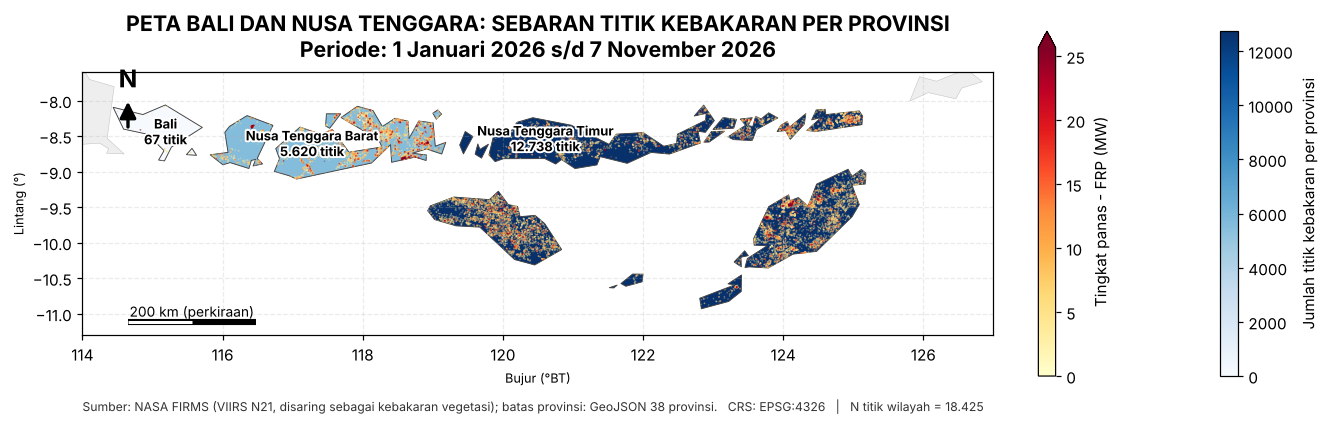

> **Artinya**
>
> Peta di atas memperbesar **Bali dan Nusa Tenggara**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.
>
> Di Bali dan Nusa Tenggara tercatat **18.425 titik kebakaran**, atau **3,2%** dari seluruh titik di Indonesia. Provinsi terbanyak adalah **Nusa Tenggara Timur** (12.738 titik, 69,1% dari wilayah ini). Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **Nusa Tenggara Barat** (2.996,5 titik per 10.000 km²). Semua provinsi di sini punya titik kebakaran. Rata-rata tingkat panas (FRP) wilayah ini 8,1 MW, dibanding 8,3 MW secara nasional; titik terbesar 373,4 MW di Nusa Tenggara Timur.
>
> Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak).

,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Nusa Tenggara Timur,12738,"46,303.45","2,750.98",7.78,373.36
2,Nusa Tenggara Barat,5620,"18,755.12","2,996.51",8.91,313.13
3,Bali,67,"5,183.60",129.25,4.82,41.56


In [33]:
peta_wilayah("Bali dan Nusa Tenggara", WILAYAH["Bali dan Nusa Tenggara"])
ringkasan_wilayah("Bali dan Nusa Tenggara", WILAYAH["Bali dan Nusa Tenggara"])

### 7.4 Kalimantan

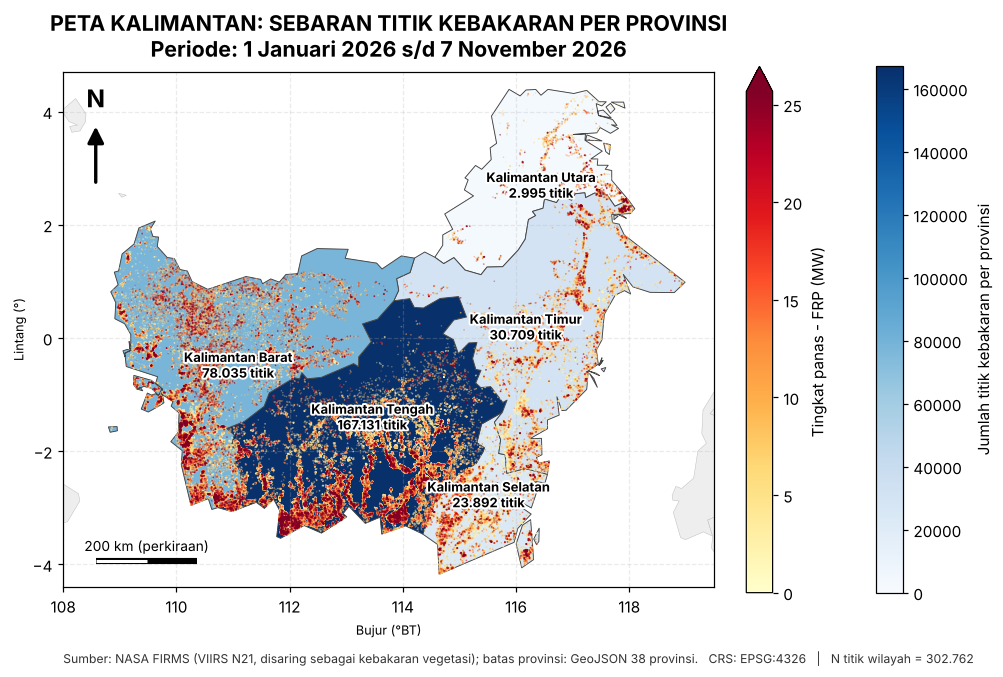

> **Artinya**
>
> Peta di atas memperbesar **Kalimantan**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.
>
> Di Kalimantan tercatat **302.762 titik kebakaran**, atau **52,2%** dari seluruh titik di Indonesia. Provinsi terbanyak adalah **Kalimantan Tengah** (167.131 titik, 55,2% dari wilayah ini). Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **Kalimantan Tengah** (10.881,2 titik per 10.000 km²). Semua provinsi di sini punya titik kebakaran. Rata-rata tingkat panas (FRP) wilayah ini 8,6 MW, dibanding 8,3 MW secara nasional; titik terbesar 792,3 MW di Kalimantan Tengah.
>
> Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak).

,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Kalimantan Tengah,167131,"153,596.08","10,881.20",8.05,792.28
2,Kalimantan Barat,78035,"147,069.33","5,306.00",10.30,515.98
3,Kalimantan Timur,30709,"124,964.65","2,457.42",7.74,376.26
4,Kalimantan Selatan,23892,"36,697.32","6,510.56",7.87,649.88
5,Kalimantan Utara,2995,"69,324.49",432.03,12.52,332.65


In [34]:
peta_wilayah("Kalimantan", WILAYAH["Kalimantan"])
ringkasan_wilayah("Kalimantan", WILAYAH["Kalimantan"])

### 7.5 Sulawesi

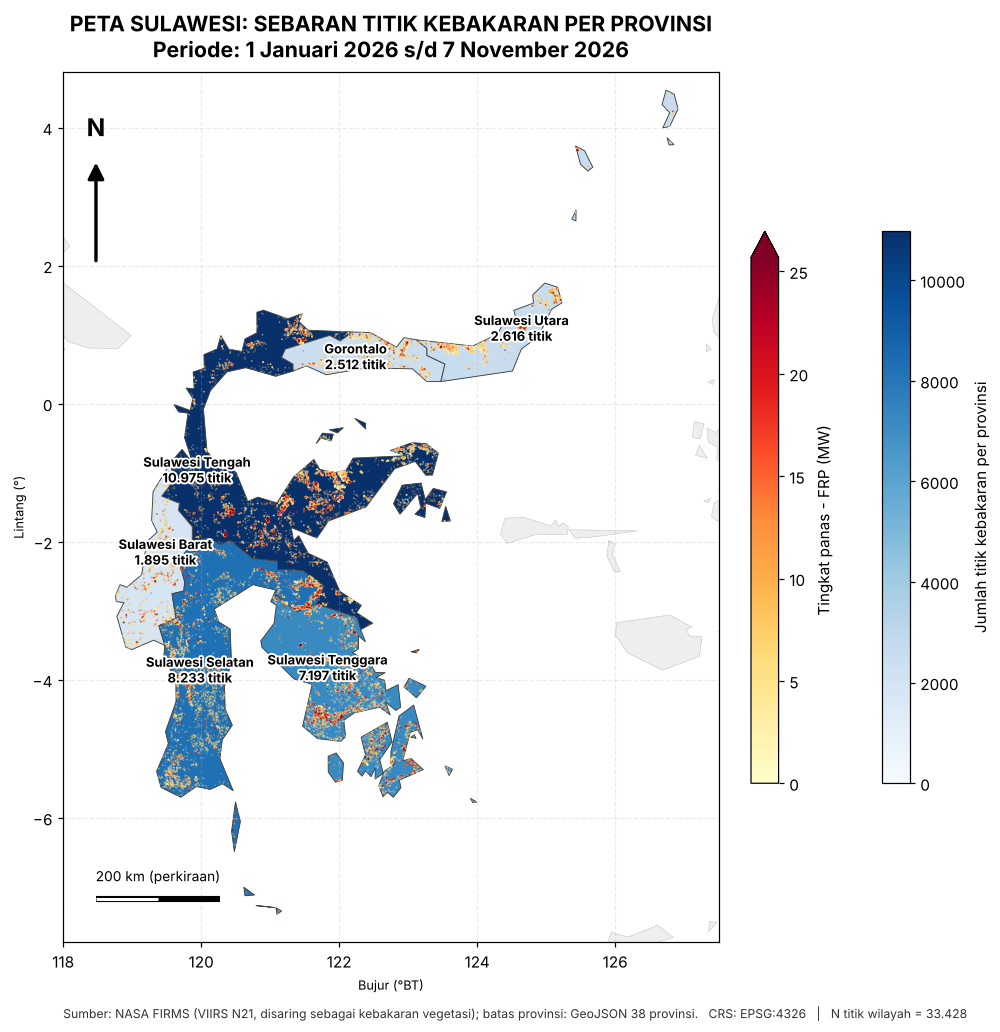

> **Artinya**
>
> Peta di atas memperbesar **Sulawesi**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.
>
> Di Sulawesi tercatat **33.428 titik kebakaran**, atau **5,8%** dari seluruh titik di Indonesia. Provinsi terbanyak adalah **Sulawesi Tengah** (10.975 titik, 32,8% dari wilayah ini). Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **Gorontalo** (2.086,0 titik per 10.000 km²). Semua provinsi di sini punya titik kebakaran. Rata-rata tingkat panas (FRP) wilayah ini 7,6 MW, dibanding 8,3 MW secara nasional; titik terbesar 295,0 MW di Sulawesi Tengah.
>
> Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak).

,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Sulawesi Tengah,10975,"59,562.56","1,842.60",8.09,294.98
2,Sulawesi Selatan,8233,"44,461.07","1,851.73",6.84,223.50
3,Sulawesi Tenggara,7197,"35,027.87","2,054.65",8.56,276.51
4,Sulawesi Utara,2616,"13,621.85","1,920.44",5.99,233.95
5,Gorontalo,2512,"12,042.10","2,086.02",5.99,63.29
6,Sulawesi Barat,1895,"16,994.81","1,115.05",8.08,171.79


In [35]:
peta_wilayah("Sulawesi", WILAYAH["Sulawesi"])
ringkasan_wilayah("Sulawesi", WILAYAH["Sulawesi"])

### 7.6 Maluku

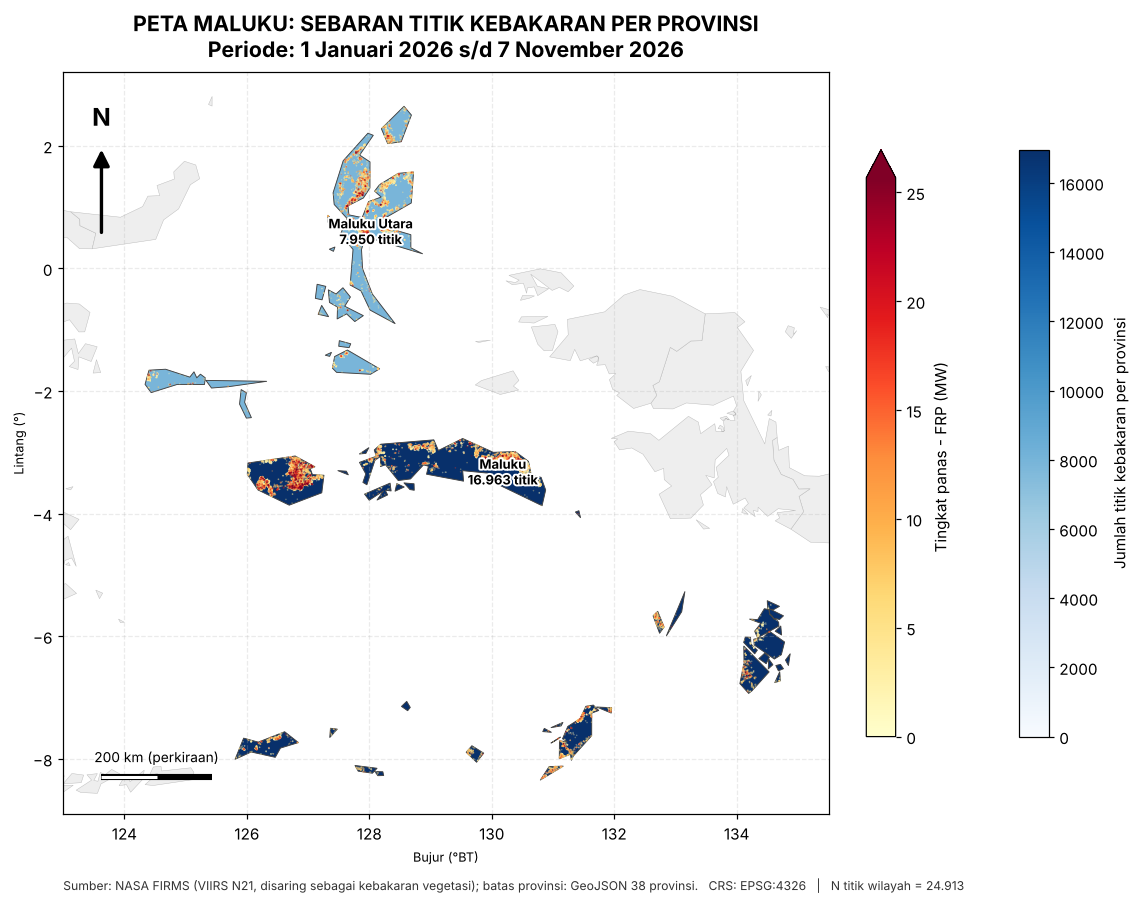

> **Artinya**
>
> Peta di atas memperbesar **Maluku**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.
>
> Di Maluku tercatat **24.913 titik kebakaran**, atau **4,3%** dari seluruh titik di Indonesia. Provinsi terbanyak adalah **Maluku** (16.963 titik, 68,1% dari wilayah ini). Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **Maluku** (4.053,0 titik per 10.000 km²). Semua provinsi di sini punya titik kebakaran. Rata-rata tingkat panas (FRP) wilayah ini 5,9 MW, dibanding 8,3 MW secara nasional; titik terbesar 326,8 MW di Maluku.
>
> Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak).

,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Maluku,16963,"41,853.15","4,052.98",6.14,326.78
2,Maluku Utara,7950,"28,642.93","2,775.55",5.31,152.63


In [36]:
peta_wilayah("Maluku", WILAYAH["Maluku"])
ringkasan_wilayah("Maluku", WILAYAH["Maluku"])

### 7.7 Papua

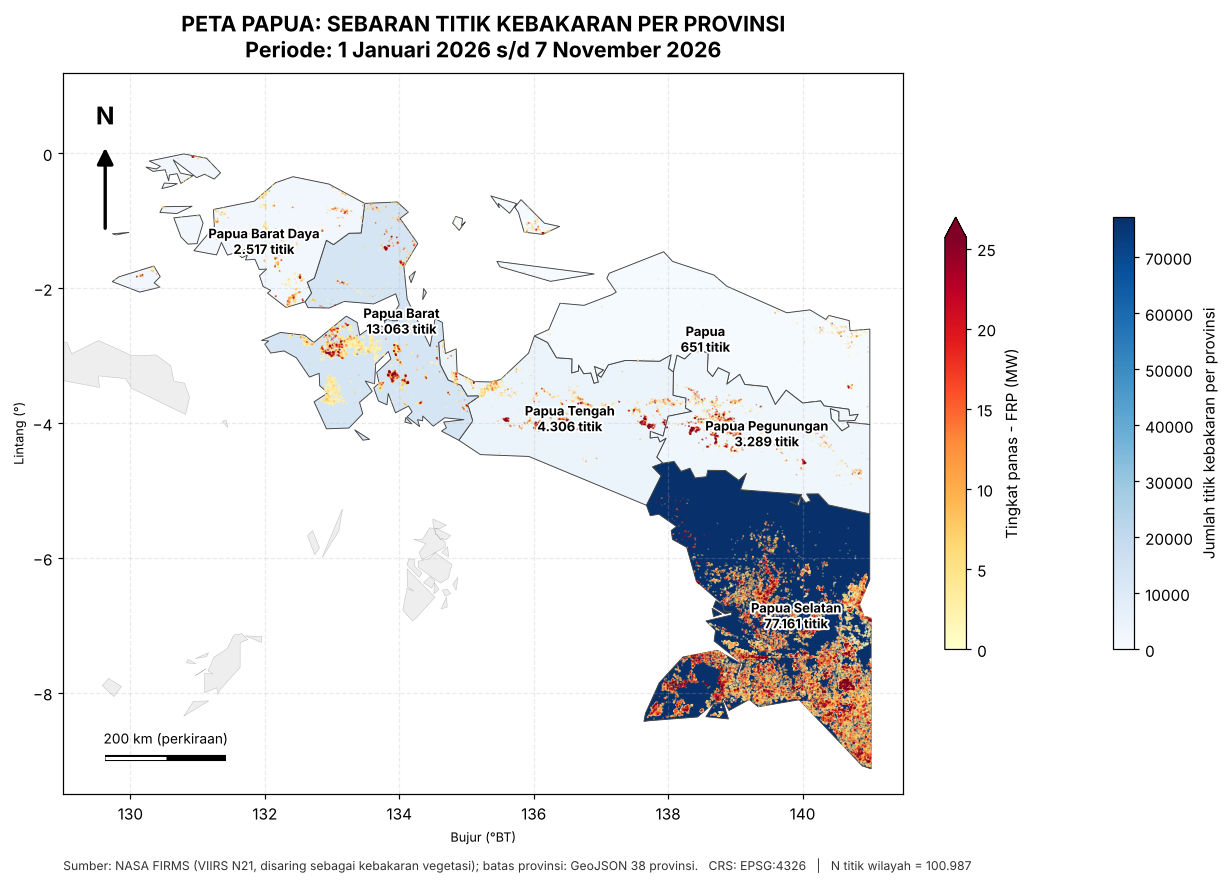

> **Artinya**
>
> Peta di atas memperbesar **Papua**. Makin gelap biru sebuah provinsi, makin banyak titik kebakarannya; makin gelap merah sebuah titik, makin besar apinya.
>
> Di Papua tercatat **100.987 titik kebakaran**, atau **17,4%** dari seluruh titik di Indonesia. Provinsi terbanyak adalah **Papua Selatan** (77.161 titik, 76,4% dari wilayah ini). Jika luas wilayah diperhitungkan, provinsi yang paling padat titik kebakarannya adalah **Papua Selatan** (6.620,3 titik per 10.000 km²). Semua provinsi di sini punya titik kebakaran. Rata-rata tingkat panas (FRP) wilayah ini 8,6 MW, dibanding 8,3 MW secara nasional; titik terbesar 527,2 MW di Papua Selatan.
>
> Tabel di bawah merinci angka tiap provinsi (urut dari titik terbanyak).

,Provinsi,Jumlah titik,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
1,Papua Selatan,77161,"116,552.22","6,620.29",8.93,527.25
2,Papua Barat,13063,"57,863.33","2,257.56",5.07,237.58
3,Papua Tengah,4306,"60,892.21",707.15,10.38,506.08
4,Papua Pegunungan,3289,"54,131.96",607.59,14.87,408.97
5,Papua Barat Daya,2517,"37,993.30",662.49,5.18,374.63
6,Papua,651,"79,770.18",81.61,6.48,73.29


In [37]:
peta_wilayah("Papua", WILAYAH["Papua"])
ringkasan_wilayah("Papua", WILAYAH["Papua"])

### 7.8 Perbandingan antarwilayah
Tabel dan grafik berikut menyatukan ketujuh wilayah agar mudah dibandingkan, termasuk **kapan** (bulan apa) tiap wilayah paling banyak titik kebakarannya.

In [38]:
baris = []
for nama, cfg in WILAYAH.items():
    sub = prov_agg[prov_agg["PROVINSI"].isin(cfg["provinsi"])]
    pts = titik_ina[titik_ina["PROVINSI"].isin(cfg["provinsi"])]
    baris.append({
        "Wilayah": nama,
        "Jumlah provinsi": len(sub),
        "Jumlah titik": len(pts),
        "% dari nasional": len(pts) / len(titik_ina) * 100,
        "Luas (km²)": sub["luas_km2"].sum(),
        "Titik / 10.000 km²": len(pts) / sub["luas_km2"].sum() * 10_000,
        "FRP rata-rata (MW)": pts["frp"].mean() if len(pts) else np.nan,
        "FRP maks (MW)": pts["frp"].max() if len(pts) else np.nan,
    })
banding = pd.DataFrame(baris).set_index("Wilayah")
display(banding)

b_tot = banding["Jumlah titik"].idxmax()
b_pad = banding["Titik / 10.000 km²"].idxmax()
b_pan = banding["FRP rata-rata (MW)"].idxmax()
jelaskan(
    "Tabel ini membandingkan ketujuh wilayah dengan ukuran yang sama. Kolom **% dari nasional** menunjukkan porsi tiap wilayah terhadap seluruh titik kebakaran Indonesia; "
    "**Titik / 10.000 km²** adalah kepadatan yang adil untuk membandingkan wilayah luas dan sempit.\n\n"
    f"Wilayah dengan titik terbanyak: **{b_tot}** ({angka(int(banding.loc[b_tot, 'Jumlah titik']))} titik, {angka(banding.loc[b_tot, '% dari nasional'], 1)}% dari nasional). "
    f"Wilayah paling padat: **{b_pad}** ({angka(banding.loc[b_pad, 'Titik / 10.000 km²'], 1)} titik per 10.000 km²). "
    f"Wilayah dengan api rata-rata paling besar: **{b_pan}** ({angka(banding.loc[b_pan, 'FRP rata-rata (MW)'], 1)} MW). "
    "Ketiganya bisa berbeda: wilayah dengan titik terbanyak belum tentu yang paling padat atau yang apinya paling besar."
)

,Jumlah provinsi,Jumlah titik,% dari nasional,Luas (km²),Titik / 10.000 km²,FRP rata-rata (MW),FRP maks (MW)
Wilayah,,,,,,,
Sumatera,10,86007,14.82,"472,036.52","1,822.04",8.45,436.55
Jawa,6,13782,2.37,"132,809.43","1,037.73",5.60,271.54
Bali dan Nusa Tenggara,3,18425,3.18,"70,242.18","2,623.07",8.11,373.36
Kalimantan,5,302762,52.17,"531,651.87","5,694.74",8.63,792.28
Sulawesi,6,33428,5.76,"181,710.27","1,839.63",7.56,294.98
Maluku,2,24913,4.29,"70,496.08","3,533.96",5.87,326.78
Papua,6,100987,17.40,"407,203.20","2,480.01",8.58,527.25


> **Artinya**
>
> Tabel ini membandingkan ketujuh wilayah dengan ukuran yang sama. Kolom **% dari nasional** menunjukkan porsi tiap wilayah terhadap seluruh titik kebakaran Indonesia; **Titik / 10.000 km²** adalah kepadatan yang adil untuk membandingkan wilayah luas dan sempit.
>
> Wilayah dengan titik terbanyak: **Kalimantan** (302.762 titik, 52,2% dari nasional). Wilayah paling padat: **Kalimantan** (5.694,7 titik per 10.000 km²). Wilayah dengan api rata-rata paling besar: **Kalimantan** (8,6 MW). Ketiganya bisa berbeda: wilayah dengan titik terbanyak belum tentu yang paling padat atau yang apinya paling besar.

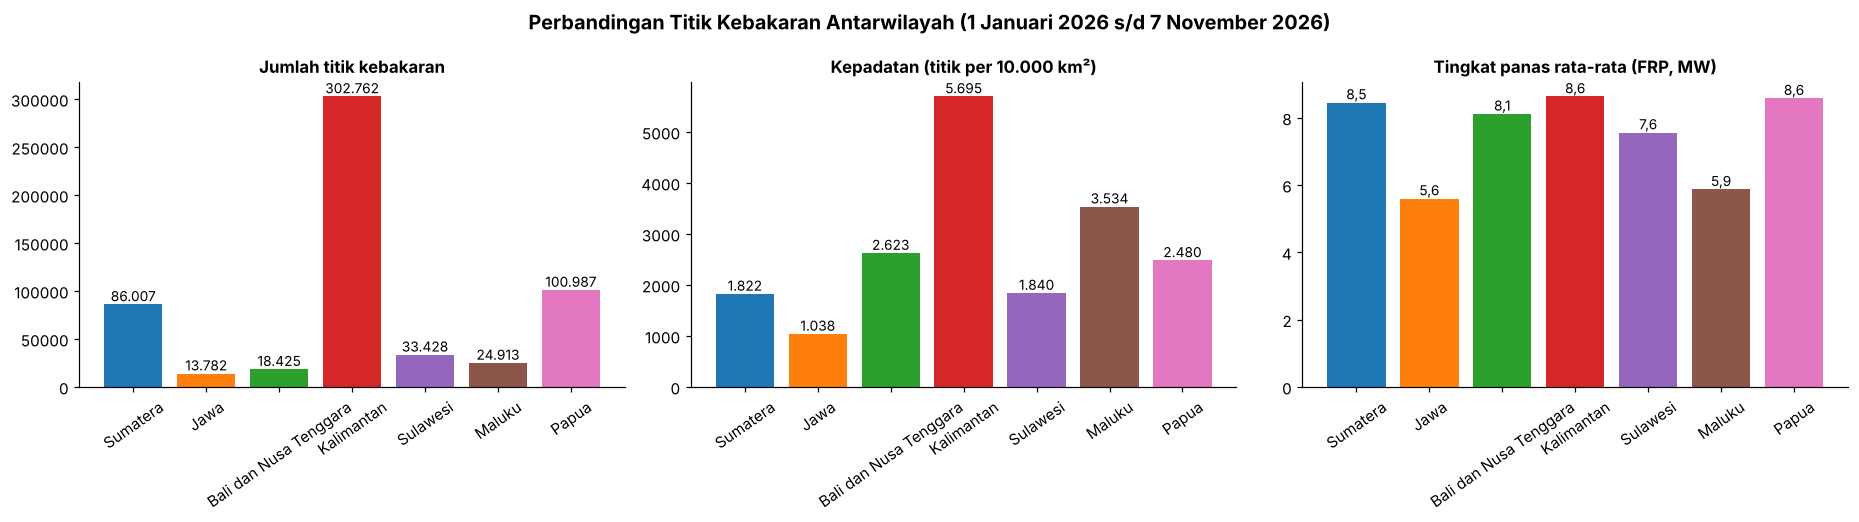

> **Artinya**
>
> Tiga grafik batang ini menampilkan tabel di atas dalam bentuk gambar. **Makin tinggi batang, makin besar nilainya.**
>
> - **Kiri**: wilayah mana yang punya titik kebakaran paling banyak (jumlah mentah).
> - **Tengah**: wilayah mana yang titik kebakarannya paling rapat jika luas diperhitungkan.
> - **Kanan**: wilayah mana yang apinya rata-rata paling besar/panas.
>
> Jika urutan wilayah di ketiga grafik berbeda-beda, artinya 'paling banyak', 'paling padat', dan 'paling panas' adalah tiga hal yang berbeda.

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
warna = plt.cm.tab10.colors[:len(banding)]

for ax, kol, jdl in zip(axes,
        ["Jumlah titik", "Titik / 10.000 km²", "FRP rata-rata (MW)"],
        ["Jumlah titik kebakaran", "Kepadatan (titik per 10.000 km²)", "Tingkat panas rata-rata (FRP, MW)"]):
    ax.bar(banding.index, banding[kol], color=warna)
    ax.set_title(jdl, fontsize=11, fontweight="bold")
    ax.tick_params(axis="x", rotation=35)
    ax.spines[["top", "right"]].set_visible(False)
    for i, v in enumerate(banding[kol].fillna(0)):
        ax.text(i, v, angka(v, 1) if v < 100 else angka(v), ha="center", va="bottom", fontsize=9)

plt.suptitle(f"Perbandingan Titik Kebakaran Antarwilayah ({PERIODE})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

jelaskan(
    "Tiga grafik batang ini menampilkan tabel di atas dalam bentuk gambar. **Makin tinggi batang, makin besar nilainya.**\n\n"
    "- **Kiri**: wilayah mana yang punya titik kebakaran paling banyak (jumlah mentah).\n"
    "- **Tengah**: wilayah mana yang titik kebakarannya paling rapat jika luas diperhitungkan.\n"
    "- **Kanan**: wilayah mana yang apinya rata-rata paling besar/panas.\n\n"
    "Jika urutan wilayah di ketiga grafik berbeda-beda, artinya 'paling banyak', 'paling padat', dan 'paling panas' adalah tiga hal yang berbeda."
)

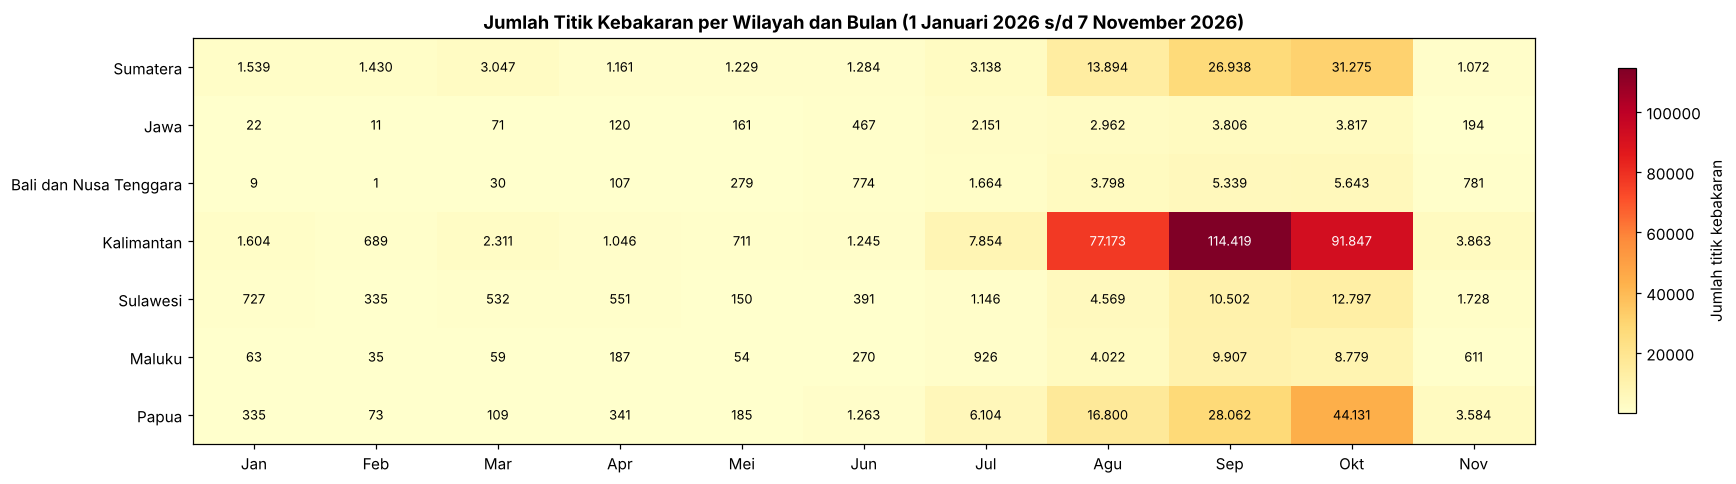

> **Artinya**
>
> Tabel warna (*heatmap*) ini mempertemukan **wilayah** (baris) dengan **bulan** (kolom). Tiap kotak berisi jumlah titik kebakaran; **makin gelap/merah kotaknya, makin banyak titik kebakaran** pada wilayah dan bulan itu.
>
> Bulan puncak tiap wilayah: **Sumatera** (Oktober); **Jawa** (Oktober); **Bali dan Nusa Tenggara** (Oktober); **Kalimantan** (September); **Sulawesi** (Oktober); **Maluku** (September); **Papua** (Oktober). Wilayah yang puncaknya berbeda bulan menunjukkan bahwa **musim api tidak serempak** di seluruh Indonesia.

In [40]:
bulan_ke_wilayah = (titik_ina.assign(bulan=titik_ina["acq_date"].dt.to_period("M"))
                    .groupby(["wilayah", "bulan"]).size().unstack(fill_value=0)
                    .reindex(index=list(WILAYAH.keys()), columns=bulan_idx, fill_value=0))

fig, ax = plt.subplots(figsize=(1.2 * max(len(bulan_idx), 4) + 4, 4.5))
im = ax.imshow(bulan_ke_wilayah.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(bulan_idx))); ax.set_xticklabels(label_bln)
ax.set_yticks(range(len(WILAYAH))); ax.set_yticklabels(WILAYAH.keys())
ambang = bulan_ke_wilayah.values.max() * 0.6
for i in range(bulan_ke_wilayah.shape[0]):
    for j in range(bulan_ke_wilayah.shape[1]):
        v = bulan_ke_wilayah.values[i, j]
        ax.text(j, i, angka(v), ha="center", va="center", fontsize=8.5,
                color="white" if v > ambang else "black")
fig.colorbar(im, ax=ax, label="Jumlah titik kebakaran", shrink=0.85)
ax.set_title(f"Jumlah Titik Kebakaran per Wilayah dan Bulan ({PERIODE})", fontweight="bold")
plt.tight_layout()
plt.show()

teks = ("Tabel warna (*heatmap*) ini mempertemukan **wilayah** (baris) dengan **bulan** (kolom). Tiap kotak berisi jumlah titik kebakaran; "
        "**makin gelap/merah kotaknya, makin banyak titik kebakaran** pada wilayah dan bulan itu.\n\n")
if len(bulan_idx) > 1:
    pk = {w: BULAN[bulan_ke_wilayah.loc[w].idxmax().month - 1] for w in WILAYAH if bulan_ke_wilayah.loc[w].sum() > 0}
    teks += "Bulan puncak tiap wilayah: " + "; ".join(f"**{w}** ({b})" for w, b in pk.items()) + ". "
    teks += ("Wilayah yang puncaknya berbeda bulan menunjukkan bahwa **musim api tidak serempak** di seluruh Indonesia."
             if len(set(pk.values())) > 1 else "Semua wilayah mencapai puncak pada bulan yang sama, jadi musim apinya relatif serempak.")
else:
    teks += "Data hanya satu bulan, jadi perbandingan antarbulan belum bisa dilakukan."
jelaskan(teks)

---
## 8. Interpretasi, keterbatasan, dan kesimpulan

In [41]:
total = len(titik_ina)
urut = prov_agg.sort_values("jumlah_titik", ascending=False)
p1, p2, p3 = urut.iloc[0], urut.iloc[1], urut.iloc[2]
kepadatan = prov_agg.sort_values("titik_per_10rbkm2", ascending=False).iloc[0]
terpanas = titik_ina.loc[titik_ina["frp"].idxmax()]

ringkasan = (
    f"- Periode data: **{PERIODE}** ({angka(n_hari)} hari), satelit **{SATELIT_PAKAI}**.\n"
    f"- Alur penyaringan: **{angka(FUNNEL[0][1])}** baris mentah menjadi **{angka(FUNNEL[-1][1])}** titik kebakaran di dalam provinsi ({pct(FUNNEL[-1][1] / FUNNEL[0][1])} dari data mentah).\n"
    f"- Total titik kebakaran di Indonesia (keyakinan nominal/high): **{angka(total)} titik**.\n"
    f"- Provinsi terbanyak: **{p1['PROVINSI']}** ({angka(int(p1['jumlah_titik']))} titik, {pct(p1['jumlah_titik'] / total)} dari total); "
    f"berikutnya {p2['PROVINSI']} ({angka(int(p2['jumlah_titik']))}) dan {p3['PROVINSI']} ({angka(int(p3['jumlah_titik']))}).\n"
    f"- Provinsi paling padat titik kebakarannya: **{kepadatan['PROVINSI']}** ({angka(kepadatan['titik_per_10rbkm2'], 1)} titik per 10.000 km²).\n"
    f"- Titik terpanas: **{angka(terpanas['frp'], 1)} MW** di {terpanas['PROVINSI']} (tanggal {tgl_id(terpanas['acq_date'])}).\n"
    f"- Provinsi tanpa titik kebakaran: **{int((prov_agg['jumlah_titik'] == 0).sum())} dari {len(prov_agg)}**.\n"
    f"- Wilayah dengan titik terbanyak: **{banding['Jumlah titik'].idxmax()}**; paling padat: **{banding['Titik / 10.000 km²'].idxmax()}**.\n"
)
if len(bulan_idx) > 1:
    ringkasan += f"- Bulan dengan titik kebakaran terbanyak: **{BULAN[puncak.month - 1]}** ({angka(int(bulanan.loc[puncak, 'jumlah']))} titik).\n"
print(ringkasan.replace("**", ""))

jelaskan("Berikut ringkasan seluruh hasil dalam satu daftar, supaya mudah dikutip di laporan:\n\n" + ringkasan)

- Periode data: 1 Januari 2026 s/d 7 November 2026 (311 hari), satelit N21.
- Alur penyaringan: 661.138 baris mentah menjadi 580.304 titik kebakaran di dalam provinsi (87,8% dari data mentah).
- Total titik kebakaran di Indonesia (keyakinan nominal/high): 580.304 titik.
- Provinsi terbanyak: Kalimantan Tengah (167.131 titik, 28,8% dari total); berikutnya Kalimantan Barat (78.035) dan Papua Selatan (77.161).
- Provinsi paling padat titik kebakarannya: Kalimantan Tengah (10.881,2 titik per 10.000 km²).
- Titik terpanas: 792,3 MW di Kalimantan Tengah (tanggal 22 September 2026).
- Provinsi tanpa titik kebakaran: 0 dari 38.
- Wilayah dengan titik terbanyak: Kalimantan; paling padat: Kalimantan.
- Bulan dengan titik kebakaran terbanyak: September (198.973 titik).



> **Artinya**
>
> Berikut ringkasan seluruh hasil dalam satu daftar, supaya mudah dikutip di laporan:
>
> - Periode data: **1 Januari 2026 s/d 7 November 2026** (311 hari), satelit **N21**.
> - Alur penyaringan: **661.138** baris mentah menjadi **580.304** titik kebakaran di dalam provinsi (87,8% dari data mentah).
> - Total titik kebakaran di Indonesia (keyakinan nominal/high): **580.304 titik**.
> - Provinsi terbanyak: **Kalimantan Tengah** (167.131 titik, 28,8% dari total); berikutnya Kalimantan Barat (78.035) dan Papua Selatan (77.161).
> - Provinsi paling padat titik kebakarannya: **Kalimantan Tengah** (10.881,2 titik per 10.000 km²).
> - Titik terpanas: **792,3 MW** di Kalimantan Tengah (tanggal 22 September 2026).
> - Provinsi tanpa titik kebakaran: **0 dari 38**.
> - Wilayah dengan titik terbanyak: **Kalimantan**; paling padat: **Kalimantan**.
> - Bulan dengan titik kebakaran terbanyak: **September** (198.973 titik).

### 8.1 Cara membaca hasil secara keseluruhan
- **Sebaran tidak merata.** Titik kebakaran terkonsentrasi pada beberapa provinsi, sedangkan provinsi lainnya jauh lebih sedikit (lihat Bagian 3 dan Peta 1).
- **Jumlah titik tidak sama dengan kepadatan.** Provinsi luas cenderung punya titik lebih banyak. Ukuran *titik per 10.000 km²* membantu membandingkan dengan adil.
- **Tingkat panas (FRP) tidak selalu sejalan dengan jumlah titik.** Wilayah dengan banyak titik bisa didominasi api kecil, sedangkan beberapa titik tunggal bisa sangat besar (Peta 2).
- **Waktu penting.** Jumlah titik kebakaran berubah dari bulan ke bulan dan berbeda antarwilayah (Bagian 4 dan 7.8), sehingga gambaran satu hari tidak mewakili keseluruhan tahun.

### 8.2 Keterbatasan
1. **Titik kebakaran di sini adalah hasil deteksi satelit, bukan verifikasi lapangan.** Penyaringan (Bagian 1.6 dan 1.8) membuang gunung api, sumber panas statis, deteksi lepas pantai, dan titik berkeyakinan rendah, tetapi tidak menjamin setiap titik adalah kebakaran hutan: pembakaran lahan terkendali, kebakaran kecil, atau deteksi keliru tetap mungkin masih terhitung.
2. **Data NRT bersifat sementara** (1 Agustus sampai 7 November 2026) dan dapat diproses ulang NASA. Perbedaan pemrosesan antara data arsip dan data NRT dapat sedikit memengaruhi perbandingan antarbulan.
3. **Penyaringan NRT berbasis lokasi tidak mengenali sumber panas statis yang baru muncul** setelah data arsip berakhir, dan bisa membuang sebagian kecil kebakaran sungguhan yang kebetulan berada di dekat sumber statis (hasil ujinya dilaporkan di Bagian 1.6).
4. **Satu satelit, waktu lintasan terbatas.** Api yang menyala di luar jam lintasan satelit tidak terdeteksi, dan awan tebal dapat menutupi api. Jumlah titik adalah indikator, bukan jumlah kebakaran yang sebenarnya.
5. **Poligon provinsi disederhanakan.** Titik di dekat garis pantai bisa jatuh di luar poligon dan terbuang, dan luas provinsi bersifat perkiraan. Batas ini juga bukan data resmi BIG.
6. **Cakupan waktu mengikuti data.** Tahun 2026 belum berakhir, sehingga hasil hanya berlaku sampai tanggal terakhir data.
7. **Skala peta perkiraan** karena memakai CRS geografis (derajat).

### 8.3 Kesimpulan
1. Dataset NASA FIRMS (VIIRS NOAA-21) memiliki informasi geometry lengkap (longitude dan latitude) dan berhasil dikonversi menjadi `GeoDataFrame` bertipe `Point`. Data disaring dari titik panas mentah menjadi **titik kebakaran vegetasi** dengan membuang sumber panas non-kebakaran dan titik berkeyakinan rendah.
2. CRS yang digunakan adalah **EPSG:4326 (WGS 84)**, yaitu CRS asli data dan batas provinsi; **EPSG:6933** (equal-area) dipakai khusus untuk menghitung luas.
3. Dengan **spatial join** dan agregasi, titik kebakaran dihitung per provinsi dan divisualisasikan sebagai **peta choropleth**; tingkat panas ditampilkan lewat warna titik berdasarkan FRP.
4. Peta akhir dilengkapi judul, legenda, north arrow, skala, grid koordinat, serta keterangan sumber dan CRS sesuai ketentuan soal. Analisis tren waktu dan peta per wilayah melengkapi gambaran sebarannya.

### 8.4 Pemeriksaan akhir terhadap ketentuan soal
| Ketentuan dosen | Status | Bukti di notebook |
|---|---|---|
| Dataset titik-titik kebakaran hutan di Indonesia | Terpenuhi | Bagian 1: NASA FIRMS VIIRS NOAA-21, disaring menjadi titik kebakaran vegetasi |
| Memiliki informasi geometry (longitude dan latitude) | Terpenuhi | Bagian 1.5 (validasi koordinat) dan 1.7 (`GeoDataFrame` bertipe `Point`) |
| Menentukan CRS dengan salah satu sistem EPSG | Terpenuhi | Bagian 2: EPSG:4326 beserta alasan; EPSG:6933 untuk luas |
| Peta lokasi kebakaran dengan gradasi warna (choropleth) | Terpenuhi | Bagian 5 (Peta 1 dan Peta 2) dan Bagian 6 (peta akhir) |
| Legenda, north arrow, judul, dan sebagainya | Terpenuhi | Bagian 6 dan 7: legenda, colorbar, north arrow, skala, judul, grid, sumber, CRS |
| Dataset terkini (terbaru) | Terpenuhi | Data sampai 7 November 2026 (Bagian 1.2 dan 1.3) |
| Menggunakan Python | Terpenuhi | Seluruh analisis dan peta dibuat dengan pandas, GeoPandas, dan Matplotlib |
| Deliverable 1: Jupyter notebook | Terpenuhi | File notebook ini |
| Deliverable 2: dataset + URL di notebook | Terpenuhi | Tabel "Sumber dataset dan URL" di Bagian 1.1; file `DL_FIRE_J2V-C2_840020.zip` |
| Deliverable 3: peta png atau jpeg | Terpenuhi | `peta_titik_kebakaran_indonesia_2026.png` dan peta wilayah (Bagian 6, 7, dan 9) |

### Referensi
- NASA FIRMS — https://firms.modaps.eosdis.nasa.gov
- GeoPandas documentation — https://geopandas.org
- GeoJSON batas 38 provinsi Indonesia — https://github.com/denyherianto/indonesia-geojson-topojson-maps-with-38-provinces

---
## 9. Unduh hasil (semua gambar)
Sel di bawah mengemas **semua gambar** (grafik dan peta) menjadi satu file zip. Di Google Colab, file zip akan **langsung terunduh** ke komputermu (izinkan unduhan jika browser meminta). Di komputer sendiri, file zip tersimpan di folder notebook.

Jika unduhan otomatis tidak jalan di Colab, buka panel **File** (ikon folder di kiri), klik titik tiga di samping file zip, lalu pilih **Download**.

In [42]:
import glob

berkas = sorted(glob.glob("gambar_output/*.png")) + sorted(glob.glob("peta_*_2026.png"))
NAMA_ZIP = "hasil_gambar_titik_kebakaran_2026.zip"

with zipfile.ZipFile(NAMA_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for f in berkas:
        z.write(f)

print(f"Jumlah gambar dalam zip : {len(berkas)}")
print(f"Ukuran file zip         : {os.path.getsize(NAMA_ZIP) / 1e6:.1f} MB")
print("Isi zip:")
for f in berkas:
    print("  -", f)

try:
    from google.colab import files as colab_files
    colab_files.download(NAMA_ZIP)
except ImportError:
    print(f"\nBukan Google Colab: file zip tersimpan di folder notebook ({NAMA_ZIP}).")

jelaskan(
    f"Semua gambar yang muncul di notebook ini (**{len(berkas)} file**) otomatis disimpan sebagai PNG dan dikemas dalam satu zip bernama **{NAMA_ZIP}**. "
    "Isinya: grafik-grafik analisis, peta nasional, dan peta tiap wilayah. "
    "File berawalan **peta_** adalah peta beresolusi tinggi (300 dpi) yang cocok untuk dicetak atau ditempel ke laporan; "
    "file di folder **gambar_output** beresolusi 200 dpi dan diberi nomor urut sesuai urutan di notebook."
)

Jumlah gambar dalam zip : 27
Ukuran file zip         : 16.0 MB
Isi zip:
  - gambar_output/01_Jenis_sumber_panas_pada_data_arsip.png
  - gambar_output/02_Jumlah_titik_menurut_tingkat_keyakinan_confidence.png
  - gambar_output/03_Alur_Penyaringan_dari_Titik_Panas_Mentah_ke_Titik_Kebakaran.png
  - gambar_output/04_10_Provinsi_dengan_Titik_Kebakaran_Terbanyak.png
  - gambar_output/05_Jumlah_Titik_Kebakaran_per_Hari_di_Indonesia_1_Januari_2026_s_d_7_Nove.png
  - gambar_output/06_Tren_Bulanan_1_Januari_2026_s_d_7_November_2026.png
  - gambar_output/07_Tren_Bulanan_5_Provinsi_dengan_Titik_Kebakaran_Terbanyak.png
  - gambar_output/08_Peta_1_Choropleth_Jumlah_Titik_Kebakaran_per_Provinsi.png
  - gambar_output/09_Peta_2_Titik_Kebakaran_Menurut_Tingkat_Panas_FRP.png
  - gambar_output/10_PETA_SEBARAN_TITIK_KEBAKARAN_HUTAN_DAN_LAHAN_DI_INDONESIA.png
  - gambar_output/11_PETA_SUMATERA_SEBARAN_TITIK_KEBAKARAN_PER_PROVINSI.png
  - gambar_output/12_PETA_JAWA_SEBARAN_TITIK_KEBAKARAN_PER_PROVINSI.png
  -

> **Artinya**
>
> Semua gambar yang muncul di notebook ini (**27 file**) otomatis disimpan sebagai PNG dan dikemas dalam satu zip bernama **hasil_gambar_titik_kebakaran_2026.zip**. Isinya: grafik-grafik analisis, peta nasional, dan peta tiap wilayah. File berawalan **peta_** adalah peta beresolusi tinggi (300 dpi) yang cocok untuk dicetak atau ditempel ke laporan; file di folder **gambar_output** beresolusi 200 dpi dan diberi nomor urut sesuai urutan di notebook.